# Biomarkers on real segmentations — analysis

The configuration is on [biomarker-real-docs.md](../docs/benchmarks/biomarker-real-docs.md) and the
conclusions on [biomarker-real-results.md](../docs/benchmarks/biomarker-real-results.md). This
notebook is where the judgement behind them is made.

**The question.** Every biomarker is computed twice on each photograph: on the **expert's**
artery/vein map, and on a **segmentation model's** map of the same photograph. The program, the
optic disc, the field of view and the microns-per-pixel scale are the same both times, so any
difference between the two numbers comes from the vessel map alone.

**Each project is read on its own segmentation model** — the one its own pipeline runs, as its
authors ship it (configuration page §2.3):

| Project | Its own artery/vein model |
| --- | --- |
| ocular | OCULARNet |
| automorph, automorphalyzer, automorphclass | AutoMorph's artery/vein model |
| vascx | VascX's artery/vein ensemble |
| fundus-biomarkers | OCULARNet, which its command-line pipeline runs |

PVBM ships no artery/vein model — its users supply the masks — so it is not read here. LUNet's and
BF-Net's maps belong to no project here. The run measured every program on every model's map, and
those rows stay in `results/` for anyone who wants that comparison.

**The project is the primary index throughout, and the dataset the secondary one.** Two
statistics summarise a pair of maps:

- **ICC(A,1)**, the intraclass correlation for absolute agreement. Of the spread across
  photographs, how much is real difference between eyes rather than disagreement between the two
  maps? 1 is perfect. Below 0.75 a study could not use one map's numbers in place of the other's.
  **ICC(C,1)** is the same but forgives a constant offset.
- **SNR**, the signal-to-noise ratio. How much eyes differ (the SD across photographs on the
  expert's maps) over how much the model's map moves the number (the SD of model − expert). Below
  1, the segmentation error is larger than the differences between eyes the biomarker exists to
  detect.

Every statistic is read from the agreement tables the run wrote, under
`results/biomarker-real/<implementation>/agreement/`. Nothing here recomputes one, except where a
grouping the run does not make — a REYIA subset, say — needs one, and then it is computed by the
run's own function.

In [1]:
import csv
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image as Picture
from PIL import Image
from plotly.subplots import make_subplots


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(
        "this notebook has to be run from inside the fundus-atlas repository; "
        f"nothing above {Path.cwd()} looks like it"
    )


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_real as benchmark  # noqa: E402
from benchmarks.metrics import agreement  # noqa: E402
from biomarkers import canonical  # noqa: E402
from biomarkers.utils import catalogue  # noqa: E402

RESULTS = ROOT / "results" / benchmark.NAME
AV_RESULTS = ROOT / "results" / benchmark.SOURCE
STORE = ROOT / ".atlas_data"
KEPT = ROOT / ".atlas_runs" / "av"
EXPERT = benchmark.EXPERT
DATASETS = list(benchmark.DATASETS)
# Each project and the segmentation model it ships with, in the benchmark's own order.
NATIVE = {slug: benchmark.native(slug) for slug in benchmark.IMPLEMENTATIONS
          if benchmark.native(slug) and (RESULTS / slug).is_dir()}
PROJECTS = list(NATIVE)
if not PROJECTS:
    raise SystemExit(f"nothing in {RESULTS}: run `python -m benchmarks --benchmark {benchmark.NAME}`")
DECLARED = {slug: catalogue.load(slug).declare() for slug in PROJECTS}
PAGE = {slug: DECLARED[slug].get("page", slug) for slug in PROJECTS}
Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
# Interactive figures render in JupyterLab and VS Code; GitHub shows the PNG beside each.
pio.renderers.default = "plotly_mimetype"
# One colour per dataset, in the benchmark's order, kept from one project's figure to the next.
DATASET_COLOURS = dict(zip(DATASETS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
# Which datasets the panel tables show, pooled last.
WITH_POOLED = DATASETS + ["pooled"]


def agreement_tables() -> pd.DataFrame:
    """Every agreement row the run wrote for a project on its own model: per dataset, and pooled."""
    frames = []
    for slug in PROJECTS:
        for path in sorted((RESULTS / slug / "agreement").glob("*.csv")):
            frame = pd.read_csv(path, keep_default_na=False, na_values=[""])
            frame = frame[frame["model"] == NATIVE[slug]]
            frame.insert(0, "dataset", path.stem)
            frame.insert(0, "project", slug)
            frames.append(frame)
    found = pd.concat(frames, ignore_index=True)
    for column in ["icc_agreement", "icc_consistency", "snr", "iqr_mape", "iqr_pct", "mape_pct",
                   "relative_bias", "n", "expert_only", "model_only"]:
        found[column] = pd.to_numeric(found[column].replace("inf", np.inf), errors="coerce")
    found["family"] = found["name"].fillna("").str.split("/").str[0].replace("", "(unnamed)")
    return found


def evidence(slug: str, dataset: str) -> list[dict[str, str]]:
    """The per-map rows of one project on one dataset: the expert's and its own model's only."""
    path = RESULTS / slug / f"{dataset}.csv"
    if not path.exists():
        return []
    with open(path, newline="") as f:
        return [row for row in csv.DictReader(f) if row["source"] in (EXPERT, NATIVE[slug])]


def summaries() -> pd.DataFrame:
    rows = []
    for slug in PROJECTS:
        for path in sorted((RESULTS / slug).glob("*.json")):
            rows.append({"project": slug, "dataset": path.stem, **json.loads(path.read_text())["summary"]})
    return pd.DataFrame(rows)


def paired_values(slug: str, name: str) -> pd.DataFrame:
    """Expert and own-model values of one catalogued name, every dataset, in the catalogued unit,
    converted by the run's own rule."""
    declared = DECLARED[slug]
    owns = [own for own, catalogued in declared["names"].items() if catalogued == name]
    rows = []
    for dataset in DATASETS:
        found = evidence(slug, dataset)
        if not found:
            continue
        subset = {row["key"]: row["subset"] for row in found if row["source"] == EXPERT}
        table = benchmark._numbers(found, declared)
        for own in owns:
            expert = table.get((EXPERT, own), {})
            said = table.get((NATIVE[slug], own), {})
            for key in sorted(set(expert) & set(said)):
                rows.append({"dataset": dataset, "subset": subset.get(key, ""), "key": key,
                             "expert": expert[key], "said": said[key]})
    return pd.DataFrame(rows, columns=["dataset", "subset", "key", "expert", "said"])


AGREE = agreement_tables()
SUMMARY = summaries()
POOLED = AGREE[AGREE["dataset"] == "pooled"]
PER_DATASET = AGREE[AGREE["dataset"] != "pooled"]
# The headline panel as each project can answer it: label -> the catalogued name it is read from.
PANELS = {slug: dict(benchmark.panel_for(AGREE.loc[AGREE["project"] == slug, "name"].dropna()))
          for slug in PROJECTS}
LABELS = [label for label, _ in benchmark.PANEL]
# The expert and own-model values behind every panel cell, for the figures and the subgroups.
PAIRS = {(slug, label): paired_values(slug, name) for slug in PROJECTS for label, name in PANELS[slug].items()}
print(f"{len(PROJECTS)} projects on their own models; {len(AGREE)} agreement rows; "
      f"{sum(len(p) for p in PAIRS.values())} paired panel values")


def by_project_dataset(frame: pd.DataFrame, statistic: str, datasets=WITH_POOLED) -> pd.DataFrame:
    """One panel statistic, rows (project, dataset), columns the panel labels; a blank where the
    project computes no such biomarker."""
    rows = {}
    for slug in PROJECTS:
        for dataset in datasets:
            mine = frame[(frame["project"] == slug) & (frame["dataset"] == dataset)].set_index("name")
            rows[(slug, dataset)] = {
                label: mine[statistic].get(PANELS[slug].get(label), np.nan) if label in PANELS[slug] else np.nan
                for label in LABELS
            }
    table = pd.DataFrame(rows).T
    table.index.names = ["project", "dataset"]
    return table[LABELS]


def shown(table: pd.DataFrame, digits: int = 2) -> pd.DataFrame:
    """A table for reading: rounded, with a dash where there is no number."""
    return table.astype(float).round(digits).astype(object).where(table.notna(), "—")

6 projects on their own models; 4458 agreement rows; 15145 paired panel values


## 1. Coverage

How much was measured before any agreement is read. One row per project and dataset: the
photographs the expert's map was measured on, the maps of its own model (one per photograph the
model drew), and the maps on which the program returned nothing at all. fundus-biomarkers returns
nothing on a photograph with no microns-per-pixel scale, by design: 43 of RAV's and all of REYIA's
`magreb` subset.

In [2]:
rows = []
for slug in PROJECTS:
    for dataset in DATASETS:
        found = evidence(slug, dataset)
        expert = [row for row in found if row["source"] == EXPERT]
        mine = [row for row in found if row["source"] == NATIVE[slug]]
        rows.append({
            "project": slug, "dataset": dataset, "model": NATIVE[slug],
            "photographs": len(expert),
            "own model's maps": len(mine),
            "no map drawn": len(expert) - len(mine),
            "nothing returned, expert's map": sum(row["outcome"] == "failed" for row in expert),
            "nothing returned, own model's map": sum(row["outcome"] == "failed" for row in mine),
        })
coverage = pd.DataFrame(rows).set_index(["project", "dataset"])
coverage

model  photographs  \
project           dataset                                            
ocular            hrf                       ocularnet           45   
                  fundus-avseg              ocularnet          100   
                  avrdb                     ocularnet           99   
                  reyia                     ocularnet          554   
                  rav                       ocularnet          198   
automorph         hrf           automorph-artery-vein           45   
                  fundus-avseg  automorph-artery-vein          100   
                  avrdb         automorph-artery-vein           99   
                  reyia         automorph-artery-vein          554   
                  rav           automorph-artery-vein          198   
automorphalyzer   hrf           automorph-artery-vein           45   
                  fundus-avseg  automorph-artery-vein          100   
                  avrdb         automorph-artery-vein           99   
                  reyia         automorph-artery-vein          554   
                  rav           automorph-artery-vein          198   
automorphclass    hrf           automorph-artery-vein           45   
                  fundus-avseg  automorph-artery-vein          100   
                  avrdb         automorph-artery-vein           99   
                  reyia         automorph-artery-vein          554   
                  rav           automorph-artery-vein          198   
vascx             hrf               vascx-artery-vein           45   
                  fundus-avseg      vascx-artery-vein          100   
                  avrdb             vascx-artery-vein           99   
                  reyia             vascx-artery-vein          554   
                  rav               vascx-artery-vein          198   
fundus-biomarkers hrf                       ocularnet           45   
                  fundus-avseg              ocularnet          100   
                  avrdb                     ocularnet           99   
                  reyia                     ocularnet          554   
                  rav                       ocularnet          198   

                                own model's maps  no map drawn  \
project           dataset                                        
ocular            hrf                         45             0   
                  fundus-avseg               100             0   
                  avrdb                       99             0   
                  reyia                      554             0   
                  rav                        198             0   
automorph         hrf                         45             0   
                  fundus-avseg               100             0   
                  avrdb                       99             0   
                  reyia                      554             0   
                  rav                        198             0   
automorphalyzer   hrf                         45             0   
                  fundus-avseg               100             0   
                  avrdb                       99             0   
                  reyia                      554             0   
                  rav                        198             0   
automorphclass    hrf                         45             0   
                  fundus-avseg               100             0   
                  avrdb                       99             0   
                  reyia                      554             0   
                  rav                        198             0   
vascx             hrf                         45             0   
                  fundus-avseg               100             0   
                  avrdb                       99             0   
                  reyia                      554             0   
                  rav                        198             0   
fundus-biomarkers hrf    

### 1.1 Where the model's map produced no number and the expert's did

For each project's own panel biomarkers. A biomarker missing on a model's map is a different
failure from one that is wrong, and is never folded into the ICC: `expert_only` counts the
photographs where only the expert's map produced a value.

In [3]:
shown(by_project_dataset(AGREE, "expert_only"), 0)

CRAE  CRVE  AVR Artery fractal dimension  \
project           dataset                                                  
ocular            hrf              —     —    —                        —   
                  fundus-avseg     —     —    —                        —   
                  avrdb            —     —    —                        —   
                  reyia            —     —    —                        —   
                  rav              —     —    —                        —   
                  pooled           —     —    —                        —   
automorph         hrf              —     —    —                      0.0   
                  fundus-avseg     —     —    —                      0.0   
                  avrdb            —     —    —                      0.0   
                  reyia            —     —    —                      3.0   
                  rav              —     —    —                      0.0   
                  pooled           —     —    —                      3.0   
automorphalyzer   hrf            0.0   0.0    —                      0.0   
                  fundus-avseg   0.0   0.0    —                      0.0   
                  avrdb         19.0   2.0    —                      1.0   
                  reyia         32.0  12.0    —                      3.0   
                  rav           13.0   9.0    —                      1.0   
                  pooled        64.0  23.0    —                      5.0   
automorphclass    hrf              —     —    —                      0.0   
                  fundus-avseg     —     —    —                      0.0   
                  avrdb            —     —    —                      0.0   
                  reyia            —     —    —                      3.0   
                  rav              —     —    —                      0.0   
                  pooled           —     —    —                      3.0   
vascx             hrf            0.0   1.0    —                        —   
                  fundus-avseg   0.0   0.0    —                        —   
                  avrdb         10.0   3.0    —                        —   
                  reyia          7.0   0.0    —                        —   
                  rav            1.0   0.0    —                        —   
                  pooled        18.0   4.0    —                        —   
fundus-biomarkers hrf            0.0   0.0  0.0                      0.0   
                  fundus-avseg   0.0   0.0  0.0                      0.0   
                  avrdb          0.0   1.0  0.0                      0.0   
                  reyia          0.0   0.0  0.0                      0.0   
                  rav            0.0   0.0  0.0                      0.0   
                  pooled         0.0   1.0  0.0                      0.0   

                               Artery tortuosity  
project           dataset                         
ocular            hrf                        2.0  
                  fundus-avseg               0.0  
                  avrdb                      0.0  
                  reyia                      0.0  
                  rav                        0.0  
                  pooled                     2.0  
automorph         hrf                        0.0  
                  fundus-avseg               0.0  
                  avrdb                      0.0  
                  reyia                      3.0  
                  rav                        0.0  
                  pooled                     3.0  
automorphalyzer   hrf                        0.0  
                  fundus-avseg               0.0  
                  avrdb                      1.0  
                  reyia                      3.0  
                  rav                        1.0  
                  pooled                     5.0  
automorphclass    hrf                        0.0  
                  fundus-avseg               0.0  
                  avr

## 2. The headline panel

Five biomarkers a reader of a vascular-epidemiology paper is most likely to meet, each with its own
way of failing:

- **CRAE and CRVE** — Knudtson's central retinal artery and vein equivalents in zone B. They fail
  on a vessel's edge.
- **AVR** — their ratio. It fails on the artery/vein classification.
- **Artery fractal dimension** — box-counting over the arteries. It fails on the smallest vessels.
- **Artery tortuosity** — median arc-to-chord ratio. It fails on a broken centreline.

Each project computes some of these and not others, and where a project returns no median artery
tortuosity its length-weighted mean or its mean stands in. This table says which catalogued column
every cell below is read from; a dash is a biomarker the project does not compute.

In [4]:
pd.DataFrame({slug: {label: PANELS[slug].get(label, "—") for label in LABELS} for slug in PROJECTS}).T

,CRAE,CRVE,AVR,Artery fractal dimension,Artery tortuosity
ocular,—,—,—,—,tortuosity/hart-tau1/artery/median
automorph,—,—,—,density/box-counting/artery,tortuosity/hart-tau1/artery/mean
automorphalyzer,calibre/CRE-knudtson/artery/B,calibre/CRE-knudtson/vein/B,—,density/box-counting/artery,tortuosity/hart-tau1/artery/mean
automorphclass,—,—,—,density/box-counting/artery,tortuosity/hart-tau1/artery/length-weighted
vascx,calibre/CRE-knudtson/artery/B,calibre/CRE-knudtson/vein/B,—,—,tortuosity/hart-tau1/artery/length-weighted
fundus-biomarkers,calibre/CRE-knudtson/artery/B,calibre/CRE-knudtson/vein/B,calibre/AVR-knudtson/both/B,density/box-counting/artery,tortuosity/hart-tau1/artery/median


### 2.1 Pooled over every photograph

One row per project on its own model. Pooled means pooled on the photographs of all five datasets,
so it flatters (section 2.2) and it carries AVRDB's wide-stroke annotation (section 7.4).

In [5]:
pooled_panel = pd.concat(
    {
        "ICC(A,1)": by_project_dataset(AGREE, "icc_agreement", ["pooled"]),
        "ICC(C,1)": by_project_dataset(AGREE, "icc_consistency", ["pooled"]),
        "SNR": by_project_dataset(AGREE, "snr", ["pooled"]),
        "IQR/MAPE": by_project_dataset(AGREE, "iqr_mape", ["pooled"]),
        "bias, % of expert": 100 * by_project_dataset(AGREE, "relative_bias", ["pooled"]),
    },
    axis=1,
).droplevel("dataset")
shown(pooled_panel)

ICC(A,1)                                       \
                      CRAE  CRVE   AVR Artery fractal dimension   
project                                                           
ocular                   —     —     —                        —   
automorph                —     —     —                     0.37   
automorphalyzer       0.57  0.63     —                     0.57   
automorphclass           —     —     —                     0.52   
vascx                 0.56  0.63     —                        —   
fundus-biomarkers     0.83  0.87  0.73                      0.8   

                                    ICC(C,1)              \
                  Artery tortuosity     CRAE  CRVE   AVR   
project                                                    
ocular                         0.72        —     —     —   
automorph                      0.37        —     —     —   
automorphalyzer                0.41     0.63  0.68     —   
automorphclass                  0.5        —     —     —   
vascx                          0.71     0.59  0.64     —   
fundus-biomarkers              0.88     0.83  0.87  0.73   

                                                               SNR        \
                  Artery fractal dimension Artery tortuosity  CRAE  CRVE   
project                                                                    
ocular                                   —              0.79     —     —   
automorph                             0.62              0.37     —     —   
automorphalyzer                       0.78               0.5  1.31  1.37   
automorphclass                        0.72              0.52     —     —   
vascx                                    —              0.73  1.34  1.38   
fundus-biomarkers                     0.81              0.89  1.94  2.14   

                                                                   IQR/MAPE  \
                    AVR Artery fractal dimension Artery tortuosity     CRAE   
project                                                                       
ocular                —                        —              1.69        —   
automorph             —                     0.83              0.72        —   
automorphalyzer       —                     1.26              1.13     2.17   
automorphclass        —                     1.09              0.98        —   
vascx                 —                        —              1.52     2.56   
fundus-biomarkers  1.47                     1.71              2.17     3.07   

                                                                          \
                   CRVE   AVR Artery fractal dimension Artery tortuosity   
project                                                                    
ocular                —     —                        —              1.87   
automorph             —     —                     0.88              2.49   
automorphalyzer    2.48     —                     1.23              1.37   
automorphclass        —     —                      1.2              1.79   
vascx              2.62     —                        —              2.62   
fundus-biomarkers  3.42  2.77                     3.58              3.41   

                  bias, % of expert                                       \
                               CRAE  CRVE   AVR Artery fractal dimension   
project                                                                    
ocular                            —     —     —                        —   
automorph                         —     —     —                     -5.7   
automorphalyzer               -7.91 -6.23     —                    -5.23   
automorphclass                    —     —     —                    -5.18   
vascx                         -4.82 -2.47     —                        —   
fundus-biomarkers             -0.21  0.93 -0.83                    -0.61   

                                     
                  Artery tortuosity  
project                       

### 2.2 Project by project, dataset by dataset

Pooling widens the signal: eyes from five cohorts and many cameras differ more than eyes from one,
so a pooled ICC flatters. These per-dataset figures are the primary evidence. ICC(A,1) first, then
the SNR, then IQR/MAPE — fundus-biomarkers' own target metric, which unlike the SNR counts a
constant offset as error.

In [6]:
shown(by_project_dataset(AGREE, "icc_agreement"))

CRAE  CRVE   AVR Artery fractal dimension  \
project           dataset                                                   
ocular            hrf              —     —     —                        —   
                  fundus-avseg     —     —     —                        —   
                  avrdb            —     —     —                        —   
                  reyia            —     —     —                        —   
                  rav              —     —     —                        —   
                  pooled           —     —     —                        —   
automorph         hrf              —     —     —                     0.25   
                  fundus-avseg     —     —     —                     0.47   
                  avrdb            —     —     —                     0.22   
                  reyia            —     —     —                     0.36   
                  rav              —     —     —                     0.46   
                  pooled           —     —     —                     0.37   
automorphalyzer   hrf           0.47  0.53     —                     0.19   
                  fundus-avseg  0.32  0.48     —                     0.55   
                  avrdb         0.06   0.1     —                      0.2   
                  reyia         0.69  0.75     —                      0.4   
                  rav            0.8  0.83     —                      0.6   
                  pooled        0.57  0.63     —                     0.57   
automorphclass    hrf              —     —     —                     0.17   
                  fundus-avseg     —     —     —                     0.55   
                  avrdb            —     —     —                     0.16   
                  reyia            —     —     —                     0.37   
                  rav              —     —     —                     0.45   
                  pooled           —     —     —                     0.52   
vascx             hrf           0.54  0.42     —                        —   
                  fundus-avseg  0.38  0.56     —                        —   
                  avrdb         0.02  0.06     —                        —   
                  reyia         0.81  0.84     —                        —   
                  rav            0.8   0.8     —                        —   
                  pooled        0.56  0.63     —                        —   
fundus-biomarkers hrf           0.61  0.39  0.68                     0.35   
                  fundus-avseg   0.6  0.72  0.78                     0.66   
                  avrdb         0.39  0.51  0.41                     0.13   
                  reyia         0.86  0.86  0.81                     0.95   
                  rav           0.78  0.86  0.66                     0.75   
                  pooled        0.83  0.87  0.73                      0.8   

                               Artery tortuosity  
project           dataset                         
ocular            hrf                       0.63  
                  fundus-avseg               0.9  
                  avrdb                     0.47  
                  reyia                     0.72  
                  rav                       0.66  
                  pooled                    0.72  
automorph         hrf                       0.05  
                  fundus-avseg               0.8  
                  avrdb                      0.0  
                  reyia                     0.24  
                  rav                      -0.06  
                  pooled                    0.37  
automorphalyzer   hrf                       0.12  
                  fundus-avseg              0.84  
                  avrdb                     0.35  
                  reyia                     0.32  
                  rav                       0.62  
                  pooled                    0.41  
automorphclass    hrf                       0.23  
                  fundus-avseg    

In [7]:
shown(by_project_dataset(AGREE, "snr"))

CRAE  CRVE   AVR Artery fractal dimension  \
project           dataset                                                   
ocular            hrf              —     —     —                        —   
                  fundus-avseg     —     —     —                        —   
                  avrdb            —     —     —                        —   
                  reyia            —     —     —                        —   
                  rav              —     —     —                        —   
                  pooled           —     —     —                        —   
automorph         hrf              —     —     —                     1.34   
                  fundus-avseg     —     —     —                     1.53   
                  avrdb            —     —     —                     0.72   
                  reyia            —     —     —                     0.92   
                  rav              —     —     —                     0.81   
                  pooled           —     —     —                     0.83   
automorphalyzer   hrf           1.21  1.11     —                     1.23   
                  fundus-avseg  1.27  1.31     —                     1.72   
                  avrdb         0.85  0.78     —                     0.65   
                  reyia         1.22  1.42     —                     0.98   
                  rav           1.55  1.79     —                     1.37   
                  pooled        1.31  1.37     —                     1.26   
automorphclass    hrf              —     —     —                     1.21   
                  fundus-avseg     —     —     —                     1.67   
                  avrdb            —     —     —                     0.54   
                  reyia            —     —     —                     0.99   
                  rav              —     —     —                     0.72   
                  pooled           —     —     —                     1.09   
vascx             hrf           1.42  1.16     —                        —   
                  fundus-avseg  1.49   1.3     —                        —   
                  avrdb          1.0  0.88     —                        —   
                  reyia         1.64  1.76     —                        —   
                  rav           1.77  1.78     —                        —   
                  pooled        1.34  1.38     —                        —   
fundus-biomarkers hrf           1.46  1.11  1.42                      1.1   
                  fundus-avseg   2.2  1.67  2.24                     2.08   
                  avrdb         1.38  1.38  1.06                     1.07   
                  reyia         2.19  2.17  1.69                     3.03   
                  rav           1.77   2.2  1.34                     1.42   
                  pooled        1.94  2.14  1.47                     1.71   

                               Artery tortuosity  
project           dataset                         
ocular            hrf                       1.82  
                  fundus-avseg              2.56  
                  avrdb                      1.2  
                  reyia                     1.53  
                  rav                       1.95  
                  pooled                    1.69  
automorph         hrf                       0.66  
                  fundus-avseg              1.36  
                  avrdb                     0.04  
                  reyia                     0.62  
                  rav                       0.57  
                  pooled                    0.72  
automorphalyzer   hrf                       1.04  
                  fundus-avseg              1.89  
                  avrdb                      0.8  
                  reyia                     1.11  
                  rav                       1.26  
                  pooled                    1.13  
automorphclass    hrf                       1.08  
                  fundus-avseg    

In [8]:
shown(by_project_dataset(AGREE, "iqr_mape"))

CRAE  CRVE   AVR Artery fractal dimension  \
project           dataset                                                   
ocular            hrf              —     —     —                        —   
                  fundus-avseg     —     —     —                        —   
                  avrdb            —     —     —                        —   
                  reyia            —     —     —                        —   
                  rav              —     —     —                        —   
                  pooled           —     —     —                        —   
automorph         hrf              —     —     —                     0.57   
                  fundus-avseg     —     —     —                      1.1   
                  avrdb            —     —     —                     0.63   
                  reyia            —     —     —                     0.75   
                  rav              —     —     —                     1.21   
                  pooled           —     —     —                     0.88   
automorphalyzer   hrf           2.23  1.66     —                     0.52   
                  fundus-avseg  1.01  1.15     —                     1.18   
                  avrdb         0.38  0.48     —                     0.59   
                  reyia         2.14  2.55     —                     0.85   
                  rav           2.78  2.79     —                     1.47   
                  pooled        2.17  2.48     —                     1.23   
automorphclass    hrf              —     —     —                     0.53   
                  fundus-avseg     —     —     —                     1.17   
                  avrdb            —     —     —                     0.56   
                  reyia            —     —     —                     0.83   
                  rav              —     —     —                     1.21   
                  pooled           —     —     —                      1.2   
vascx             hrf           1.81  1.54     —                        —   
                  fundus-avseg  1.04  1.39     —                        —   
                  avrdb         0.35  0.43     —                        —   
                  reyia         3.03  3.32     —                        —   
                  rav           2.75  2.02     —                        —   
                  pooled        2.56  2.62     —                        —   
fundus-biomarkers hrf           1.88  1.56  2.33                     2.19   
                  fundus-avseg  1.36  1.61  2.17                     1.39   
                  avrdb          1.2  1.51  1.41                     0.57   
                  reyia         3.07  3.41  3.24                     5.65   
                  rav           2.59  3.39  2.31                     2.85   
                  pooled        3.07  3.42  2.77                     3.58   

                               Artery tortuosity  
project           dataset                         
ocular            hrf                       1.33  
                  fundus-avseg              2.82  
                  avrdb                     1.22  
                  reyia                     1.84  
                  rav                       1.61  
                  pooled                    1.87  
automorph         hrf                       1.41  
                  fundus-avseg               0.0  
                  avrdb                      0.0  
                  reyia                     1.72  
                  rav                        0.0  
                  pooled                    2.49  
automorphalyzer   hrf                       0.67  
                  fundus-avseg              2.33  
                  avrdb                     1.04  
                  reyia                     1.34  
                  rav                       1.65  
                  pooled                    1.37  
automorphclass    hrf                       1.23  
                  fundus-avseg    

**Reading it.**

- **Calibre survives its own model on REYIA and RAV, and fails on AVRDB, in every project that
  measures it.** CRAE reaches 0.78–0.86 for fundus-biomarkers, 0.80–0.81 for VascX and 0.69–0.80
  for AutoMorphalyzer on those two; on AVRDB it is 0.39, 0.02 and 0.06. Only fundus-biomarkers
  runs a model, OCULARNet, that trained on AVRDB.
- **VascX returns its equivalents on only part of two datasets**, on the expert's map and its own
  alike: CRAE on 44 of AVRDB's 99 photographs and 89 of RAV's 198 (155 of which have a scale). Its
  RAV figure is over those 89.
- **Tortuosity depends on which summary the project returns.** fundus-biomarkers' median holds at
  0.79–0.92 on every dataset; AutoMorph's mean ranges from −0.06 (RAV) to 0.80 (Fundus-AVSeg).
  Section 3.2.2 shows what is behind AutoMorph's figure.

### 2.3 What each ICC is made of

Every photograph, expert-map value against own-model value, one row of panels per project. The
diagonal is perfect agreement; colours are datasets. One ICC can hide a tight cloud with a few
far-off photographs, or a constant offset (a cloud parallel to the diagonal). Lengths are in
microns, converted by the run's own rule. Where a project computes no such biomarker the panel is
empty.

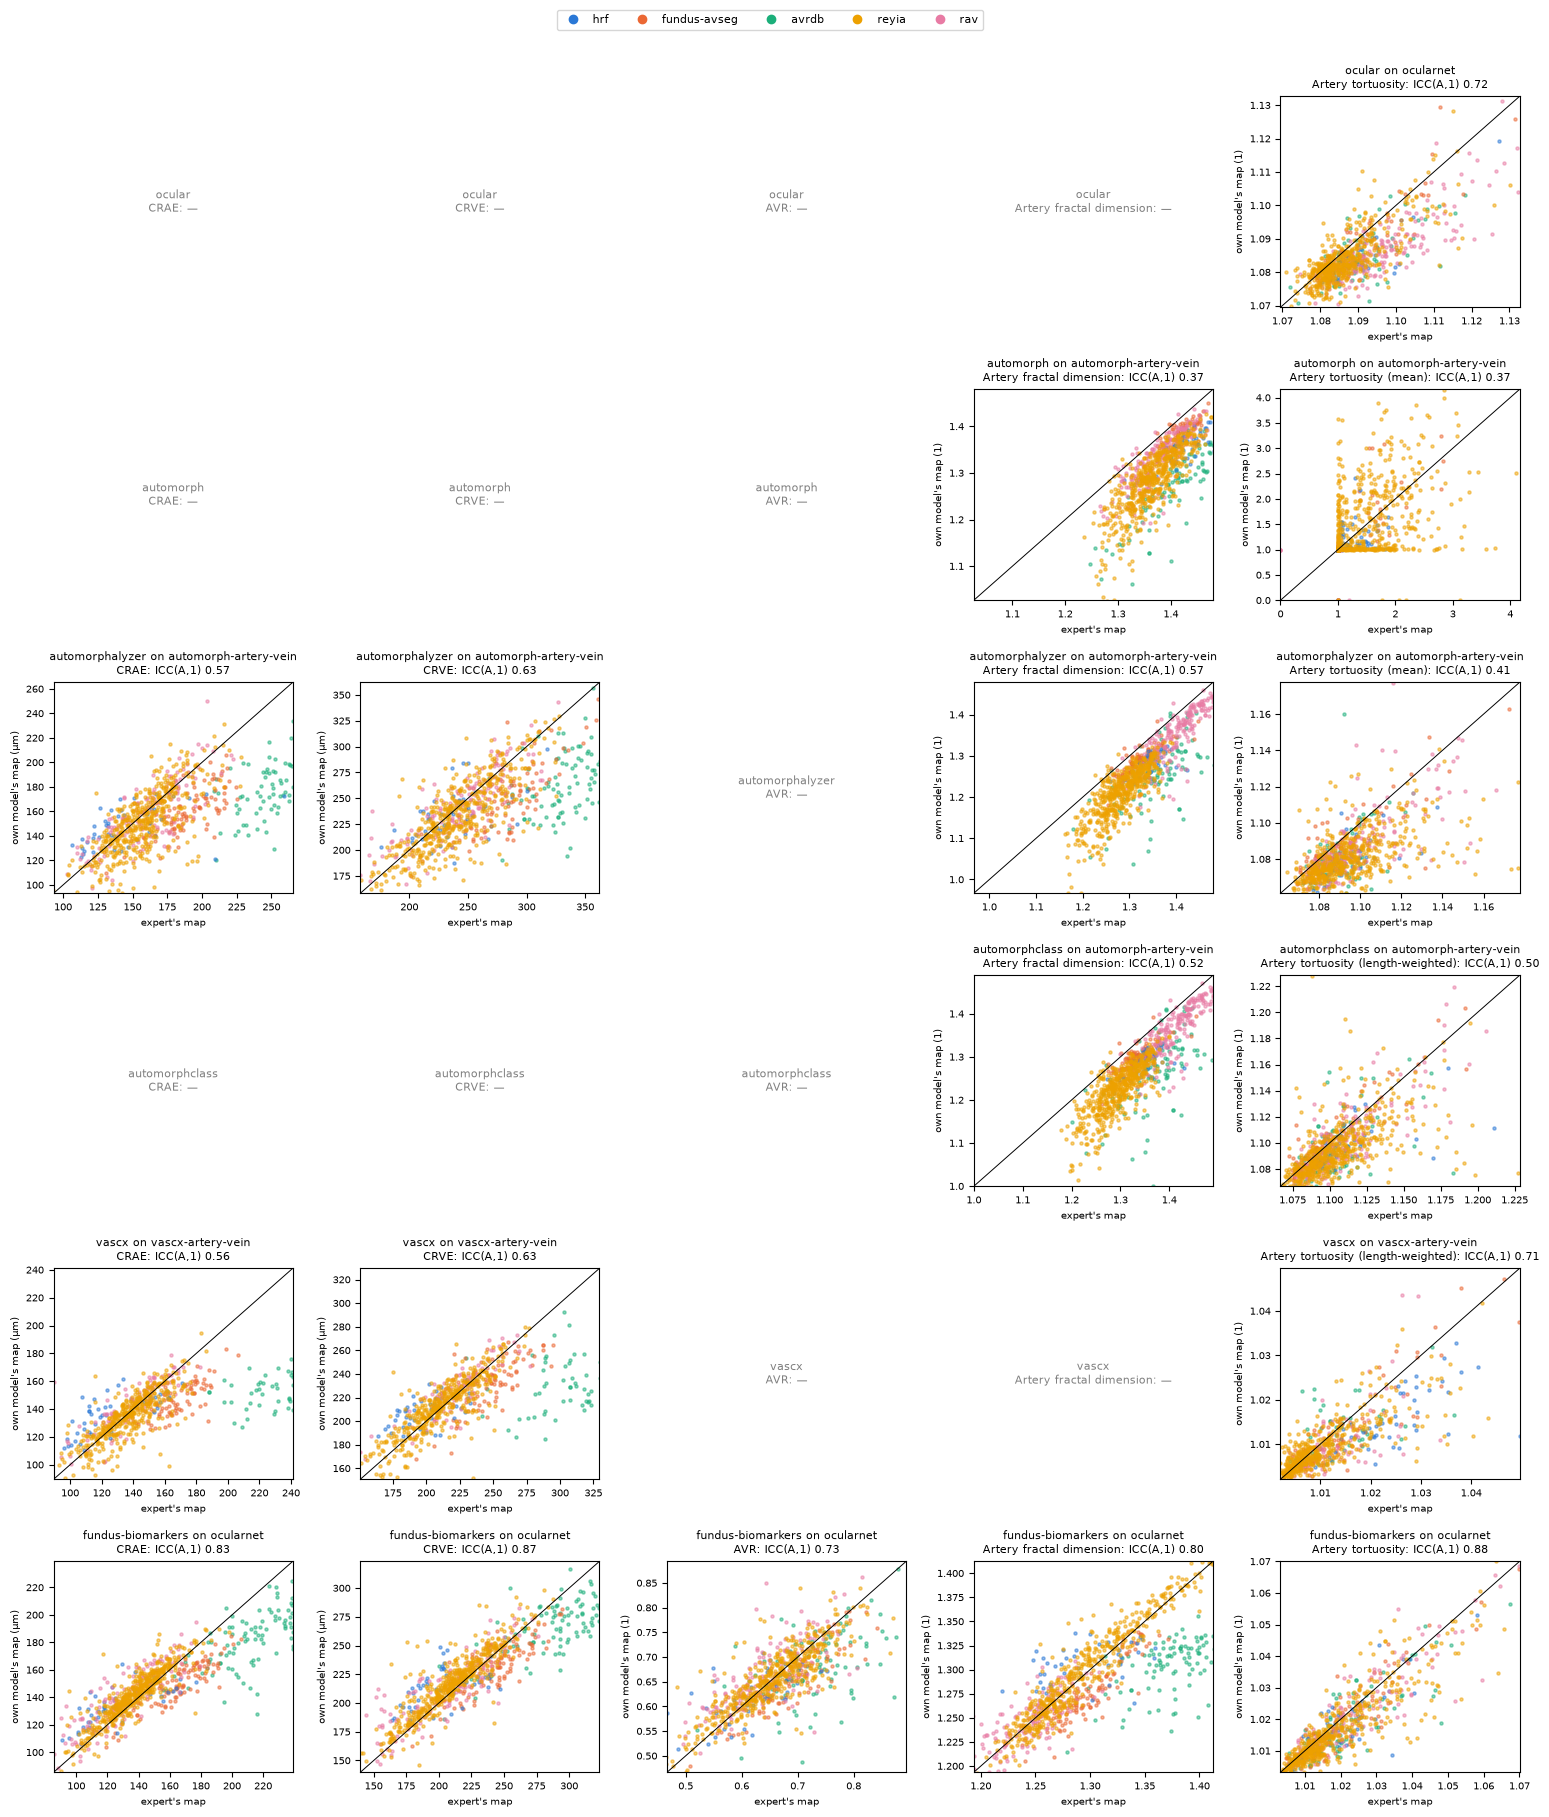

In [9]:
def panel_grid(height: float):
    figure, axes = plt.subplots(len(PROJECTS), len(LABELS), figsize=(3.1 * len(LABELS), height * len(PROJECTS)), squeeze=False)
    for row, slug in enumerate(PROJECTS):
        for column, label in enumerate(LABELS):
            if (slug, label) not in PAIRS or PAIRS[(slug, label)].empty:
                axes[row, column].axis("off")
                axes[row, column].text(0.5, 0.5, f"{slug}\n{label}: —", ha="center", va="center", fontsize=8, color="grey")
    return figure, axes


def variant(slug: str, label: str) -> str:
    name = PANELS[slug][label]
    return "" if dict(benchmark.PANEL)[label] == name else f" ({name.split('/')[-1]})"


figure, axes = panel_grid(3.0)
for row, slug in enumerate(PROJECTS):
    for column, label in enumerate(LABELS):
        pairs = PAIRS.get((slug, label))
        if pairs is None or pairs.empty:
            continue
        axis = axes[row, column]
        low, high = np.nanpercentile(np.r_[pairs["expert"], pairs["said"]], [0.5, 99.5])
        for dataset, group in pairs.groupby("dataset"):
            axis.scatter(group["expert"], group["said"], s=5, alpha=0.5, color=DATASET_COLOURS[dataset], label=dataset)
        axis.plot([low, high], [low, high], color="black", linewidth=0.7)
        axis.set_xlim(low, high)
        axis.set_ylim(low, high)
        icc = pooled_panel.loc[slug, ("ICC(A,1)", label)]
        axis.set_title(f"{slug} on {NATIVE[slug]}\n{label}{variant(slug, label)}: ICC(A,1) {icc:.2f}", fontsize=8)
        axis.set_ylabel(f"own model's map ({canonical.unit(PANELS[slug][label])})", fontsize=7)
        axis.set_xlabel("expert's map", fontsize=7)
        axis.tick_params(labelsize=7)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=d) for d, c in DATASET_COLOURS.items()]
figure.legend(handles=handles, loc="upper center", ncol=len(DATASETS), fontsize=8, bbox_to_anchor=(0.5, 1.01))
figure.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

### 2.4 Difference against mean (Bland–Altman)

The same pairs, as model − expert against their mean, so a bias that grows with the value — a
model that thins the widest vessels most, say — shows as a slope rather than a cloud. The dashed
lines are the bias and its 95% limits of agreement (bias ± 1.96 SD of the difference).

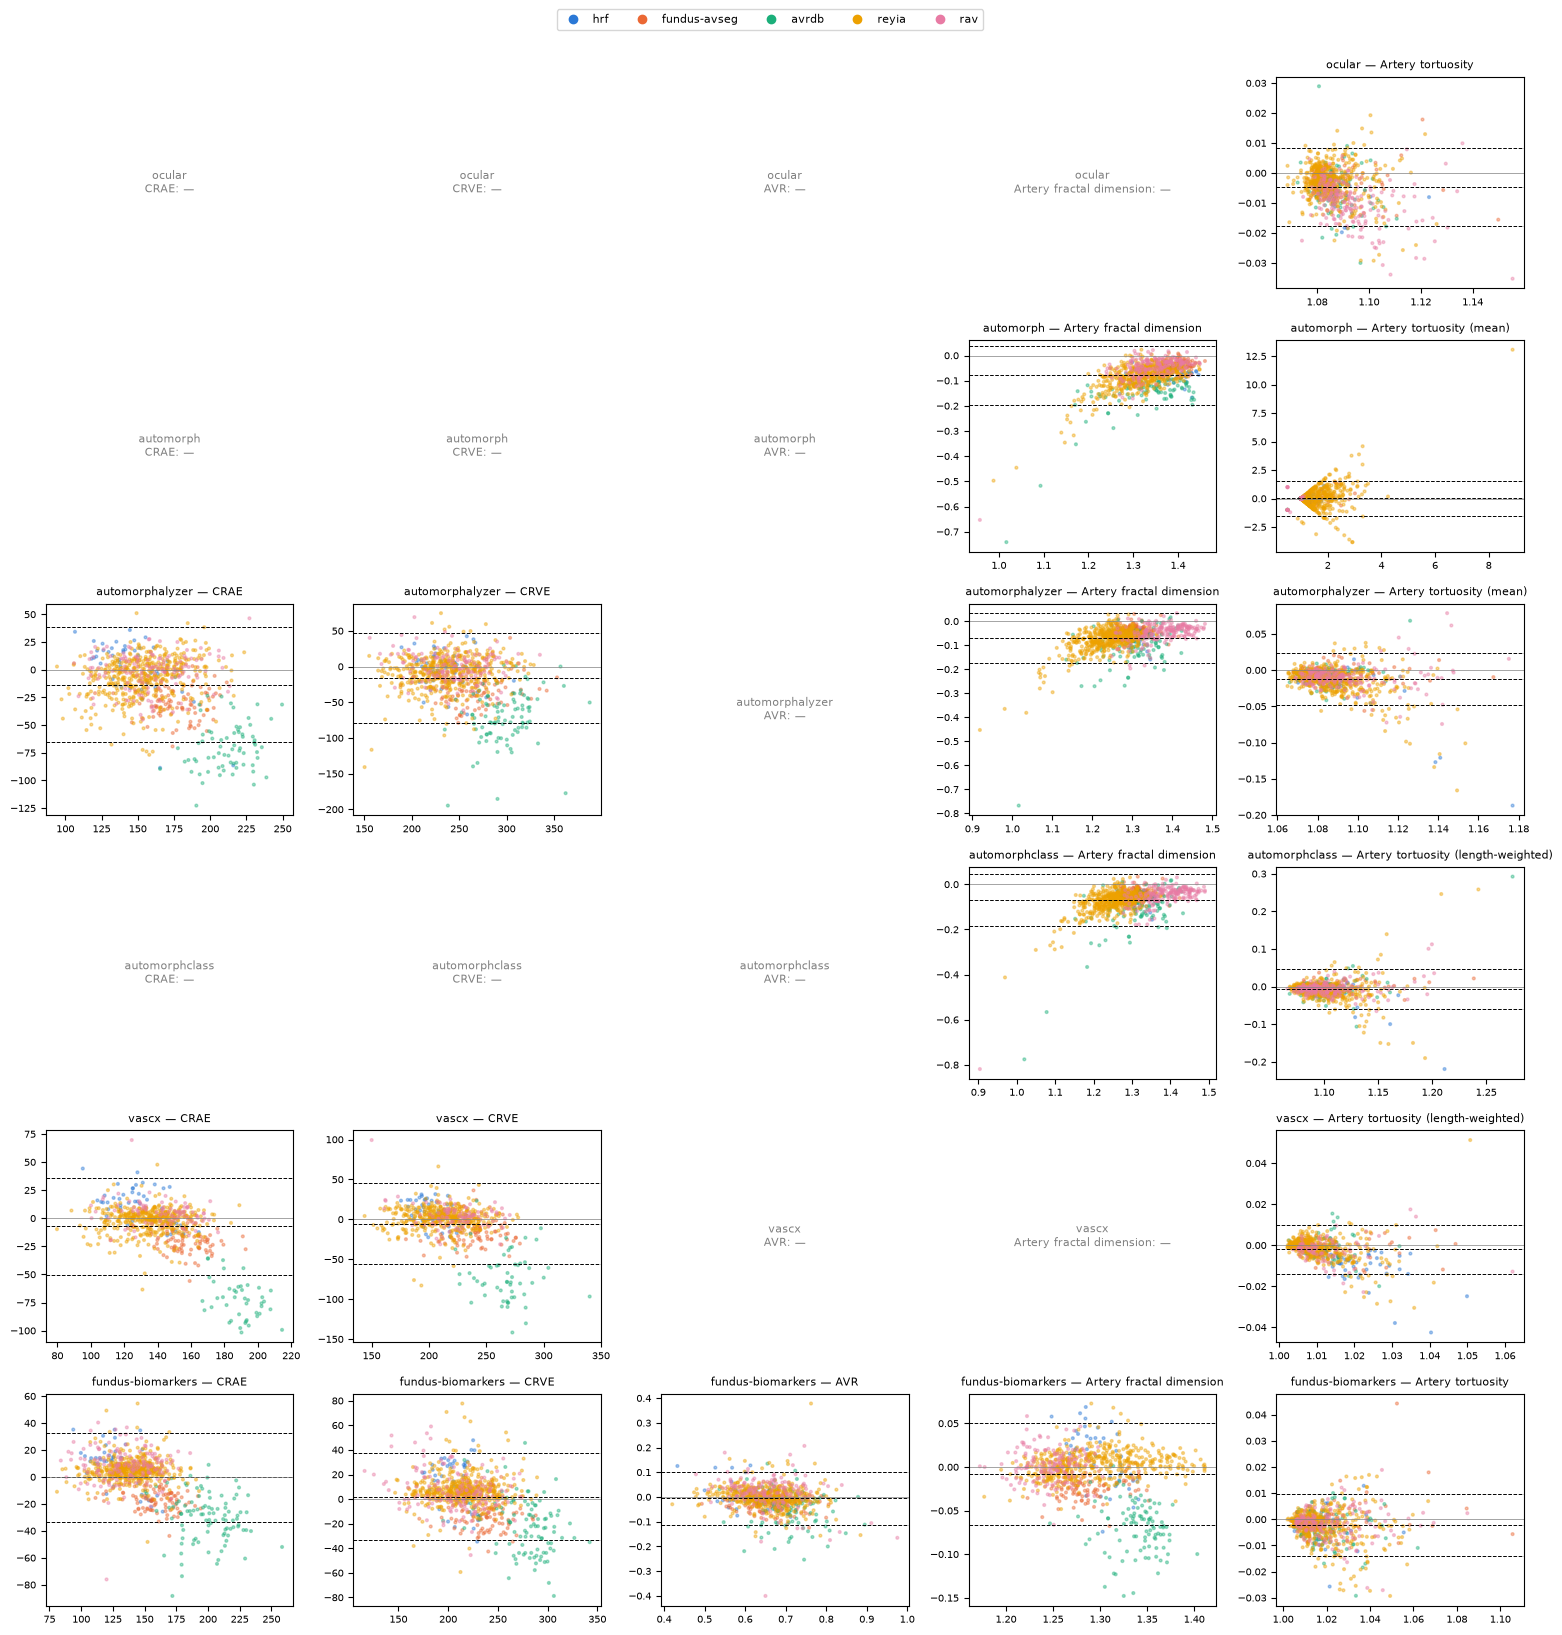

In [10]:
figure, axes = panel_grid(2.7)
for row, slug in enumerate(PROJECTS):
    for column, label in enumerate(LABELS):
        pairs = PAIRS.get((slug, label))
        if pairs is None or pairs.empty:
            continue
        axis = axes[row, column]
        mean = (pairs["expert"] + pairs["said"]) / 2
        difference = pairs["said"] - pairs["expert"]
        axis.scatter(mean, difference, s=4, alpha=0.4, color=[DATASET_COLOURS[d] for d in pairs["dataset"]])
        bias, spread = difference.mean(), difference.std()
        for level in (bias, bias - 1.96 * spread, bias + 1.96 * spread):
            axis.axhline(level, color="black", linestyle="--", linewidth=0.7)
        axis.axhline(0, color="grey", linewidth=0.5)
        axis.set_title(f"{slug} — {label}{variant(slug, label)}", fontsize=8)
        axis.tick_params(labelsize=7)
figure.legend(handles=handles, loc="upper center", ncol=len(DATASETS), fontsize=8, bbox_to_anchor=(0.5, 1.01))
figure.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

## 3. Every catalogued biomarker

The panel is five numbers out of hundreds. Here every catalogued column each project returns,
grouped by family, project by project and dataset by dataset. Each cell is the **median ICC(A,1)
across the family's columns · the share of them at 0.75 or above**, over columns measured on at
least 20 photographs. A dash is a family the project does not compute. The projects return very
different numbers of columns — fundus-biomarkers over six hundred, VascX six — so a share is over a
different set in every row.

In [11]:
NAMED = AGREE[AGREE["name"].notna() & (AGREE["n"] >= 20)]
FAMILIES = [f for f in canonical.FAMILIES if f in set(NAMED["family"])]


def family_cells(frame: pd.DataFrame, statistic: str, good) -> pd.DataFrame:
    rows = {}
    for slug in PROJECTS:
        for dataset in WITH_POOLED:
            mine = frame[(frame["project"] == slug) & (frame["dataset"] == dataset)]
            cells = {}
            for family in FAMILIES:
                values = mine.loc[mine["family"] == family, statistic].replace(np.inf, np.nan).dropna()
                cells[family] = f"{values.median():.2f} · {good(values).mean():.0%}" if len(values) else "—"
            rows[(slug, dataset)] = cells
    table = pd.DataFrame(rows).T
    table.index.names = ["project", "dataset"]
    return table


columns_per_family = NAMED[NAMED["dataset"] == "pooled"].pivot_table(
    index="project", columns="family", values="column", aggfunc="nunique").reindex(index=PROJECTS, columns=FAMILIES)
display(columns_per_family.fillna(0).astype(int).rename_axis(columns="catalogued columns per family"))
family_cells(NAMED, "icc_agreement", lambda v: v >= 0.75)

catalogued columns per family,calibre,tortuosity,density,topology
project,,,,
ocular,0,4,4,2
automorph,3,6,6,0
automorphalyzer,5,12,6,0
automorphclass,3,6,6,0
vascx,4,2,0,0
fundus-biomarkers,39,492,62,36


calibre   tortuosity      density  \
project           dataset                                              
ocular            hrf                    —    0.45 · 0%    0.36 · 0%   
                  fundus-avseg           —   0.77 · 50%   0.65 · 25%   
                  avrdb                  —    0.43 · 0%    0.57 · 0%   
                  reyia                  —   0.65 · 25%   0.83 · 50%   
                  rav                    —   0.65 · 25%  0.93 · 100%   
                  pooled                 —   0.61 · 25%   0.78 · 50%   
automorph         hrf            0.08 · 0%   -0.03 · 0%   0.44 · 17%   
                  fundus-avseg   0.47 · 0%  0.93 · 100%    0.34 · 0%   
                  avrdb          0.02 · 0%    0.00 · 0%    0.17 · 0%   
                  reyia          0.44 · 0%   0.56 · 50%    0.45 · 0%   
                  rav            0.49 · 0%   -0.02 · 0%    0.68 · 0%   
                  pooled         0.38 · 0%   0.66 · 50%    0.34 · 0%   
automorphalyzer   hrf            0.17 · 0%    0.14 · 0%    0.41 · 0%   
                  fundus-avseg   0.45 · 0%   0.85 · 75%    0.39 · 0%   
                  avrdb          0.03 · 0%    0.28 · 0%    0.17 · 0%   
                  reyia         0.45 · 20%   0.54 · 42%    0.48 · 0%   
                  rav           0.56 · 40%    0.43 · 0%   0.68 · 17%   
                  pooled         0.39 · 0%   0.63 · 50%    0.47 · 0%   
automorphclass    hrf            0.08 · 0%    0.20 · 0%    0.39 · 0%   
                  fundus-avseg   0.46 · 0%   0.97 · 83%    0.38 · 0%   
                  avrdb          0.02 · 0%    0.30 · 0%    0.16 · 0%   
                  reyia          0.44 · 0%   0.63 · 50%    0.45 · 0%   
                  rav            0.49 · 0%   0.48 · 17%    0.67 · 0%   
                  pooled         0.38 · 0%   0.72 · 50%    0.44 · 0%   
vascx             hrf            0.26 · 0%    0.40 · 0%            —   
                  fundus-avseg   0.40 · 0%   0.81 · 50%            —   
                  avrdb          0.04 · 0%   0.66 · 50%            —   
                  reyia         0.68 · 50%   0.74 · 50%            —   
                  rav           0.71 · 50%    0.65 · 0%            —   
                  pooled         0.55 · 0%   0.73 · 50%            —   
fundus-biomarkers hrf            0.39 · 3%    0.29 · 7%    0.31 · 0%   
                  fundus-avseg  0.60 · 18%   0.78 · 57%   0.72 · 44%   
                  avrdb          0.37 · 0%   0.57 · 17%   0.51 · 18%   
                  reyia         0.66 · 46%   0.77 · 54%   0.89 · 82%   
                  rav           0.67 · 33%   0.76 · 53%   0.82 · 74%   
                  pooled        0.77 · 59%   0.70 · 40%   0.81 · 77%   

                                  topology  
project           dataset                   
ocular            hrf            0.07 · 0%  
                  fundus-avseg   0.23 · 0%  
                  avrdb          0.62 · 0%  
                  reyia          0.69 · 0%  
                  rav           0.71 · 50%  
                  pooled         0.58 · 0%  
automorph         hrf                    —  
                  fundus-avseg           —  
                  avrdb                  —  
                  reyia                  —  
                  rav                    —  
                  pooled                 —  
automorphalyzer   hrf                    —  
                  fundus-avseg           —  
                  avrdb                  —  
                  reyia                  —  
                  rav                    —  
                  pooled                 —  
automorphclass    hrf                    —  
                  fundus-avseg           —  
                  avrdb                  —  
                  reyia                  —  
                  rav                    —  
                  pooled                 —  
vascx             hrf                    —  
                  fundus-avseg           —  
                  avrdb               

### 3.1 Which biomarkers survive every dataset, and which survive none

For each project on its own model: the catalogued columns whose ICC(A,1) is at least 0.9 on
**every** dataset it was measured on (with at least 20 photographs), and those under 0.5 on every
one. The first are safe to take from that project's own pipeline whichever of these cohorts a
photograph resembles. For the second, the project's own model does not reproduce what the expert's
tracing carries, on any cohort.

In [12]:
survivors = {}
for slug in PROJECTS:
    mine = NAMED[(NAMED["project"] == slug) & (NAMED["dataset"] != "pooled")]
    wide = mine.pivot_table(index="name", columns="dataset", values="icc_agreement", aggfunc="first")
    robust = wide[(wide >= 0.9).where(wide.notna()).all(axis=1) & wide.notna().any(axis=1)]
    fragile = wide[(wide < 0.5).where(wide.notna()).all(axis=1) & wide.notna().any(axis=1)]
    survivors[slug] = (wide, robust, fragile)
    print(f"{slug} on {NATIVE[slug]}: {len(robust)} of {len(wide)} catalogued columns at ICC(A,1) ≥ 0.9 "
          f"on every dataset; {len(fragile)} under 0.5 on every dataset")

ocular on ocularnet: 0 of 10 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 0 under 0.5 on every dataset
automorph on automorph-artery-vein: 0 of 15 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 3 under 0.5 on every dataset
automorphalyzer on automorph-artery-vein: 0 of 23 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 3 under 0.5 on every dataset
automorphclass on automorph-artery-vein: 0 of 15 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 2 under 0.5 on every dataset
vascx on vascx-artery-vein: 0 of 6 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 0 under 0.5 on every dataset
fundus-biomarkers on ocularnet: 0 of 629 catalogued columns at ICC(A,1) ≥ 0.9 on every dataset; 41 under 0.5 on every dataset


In [13]:
for slug, (wide, robust, fragile) in survivors.items():
    if len(robust):
        print(f"\n{slug} — at 0.9 or above on every dataset")
        display(shown(robust.reindex(columns=DATASETS)).head(25))

In [14]:
for slug, (wide, robust, fragile) in survivors.items():
    if len(fragile):
        print(f"\n{slug} — under 0.5 on every dataset")
        display(shown(fragile.reindex(columns=DATASETS)).head(25))


automorph — under 0.5 on every dataset


dataset,hrf,fundus-avseg,avrdb,reyia,rav
name,,,,,
calibre/width/artery/length-weighted,0.13,0.43,-0.01,0.44,0.35
calibre/width/vessels/length-weighted,0.08,0.47,0.02,0.44,0.49
density/box-counting/artery,0.25,0.47,0.22,0.36,0.46



automorphalyzer — under 0.5 on every dataset


dataset,hrf,fundus-avseg,avrdb,reyia,rav
name,,,,,
calibre/width/artery/length-weighted,0.17,0.4,-0.0,0.44,0.4
calibre/width/vessels/length-weighted,0.1,0.45,0.02,0.45,0.46
tortuosity/hart-tau1/vein/B/mean,0.14,0.35,0.24,0.32,0.24



automorphclass — under 0.5 on every dataset


dataset,hrf,fundus-avseg,avrdb,reyia,rav
name,,,,,
calibre/width/artery/length-weighted,0.13,0.42,-0.01,0.44,0.35
calibre/width/vessels/length-weighted,0.08,0.46,0.02,0.44,0.49



fundus-biomarkers — under 0.5 on every dataset


dataset,hrf,fundus-avseg,avrdb,reyia,rav
name,,,,,
topology/components/artery,0.37,0.09,0.11,0.23,0.13
topology/components/vein,0.13,0.2,0.3,0.31,0.26
topology/endpoints/artery/B,0.33,0.16,0.11,0.29,0.33
topology/endpoints/artery/C,0.29,0.26,0.35,0.48,0.41
topology/endpoints/vein/B,0.1,0.41,0.49,0.46,0.3
tortuosity/arc-chord-times-inflections/vein/B/median,-0.03,0.1,0.16,0.35,0.28
tortuosity/grisan-density/vein/std,0.07,0.45,0.07,0.22,0.43
tortuosity/hart-tau1/vein/C/std,0.04,0.35,0.0,0.35,0.0
tortuosity/hart-tau1/vein/length-weighted,0.18,0.16,0.14,0.36,0.32


### 3.2 IQR against MAPE, project by project

fundus-biomarkers judges a biomarker by a ratio of two percentages, and the run records both:

- **IQR (%)** — how much eyes differ from one another **on the expert's maps**: the interquartile
  range of the values over their median. This is the signal a study is looking for.
- **MAPE (%)** — the mean absolute percentage error: how far, on average, the model's map moves a
  photograph's value away from the value on the expert's map. This is the error the segmentation
  adds.

Above the dashed diagonal IQR exceeds MAPE (IQR/MAPE above 1): eyes differ more than the model's
map moves the number, so the biomarker still separates eyes when measured on that map. Below it,
the segmentation's error is as large as the differences between eyes.

Each dot is one catalogued column **on one dataset**, coloured by dataset; the drop-down at the top
right chooses the family, and hovering over a dot names the column and gives its ICC(A,1) and SNR.
The figure is interactive in JupyterLab or VS Code; on GitHub, the picture under it shows every
family side by side. Only columns measured on at least 20 photographs are drawn, and a column whose
IQR or MAPE is 0 has no place on a log scale and is counted rather than drawn.

**Why the IQRs fall into bands.** The IQR is computed from the expert's maps alone, so the model
does not move it: under one column and one dataset it is the same whichever map is compared
(across the five models the run measured, it differs by 1–2 % — only through which photographs both
maps produced a number for — where MAPE differs two- to three-fold). What moves a dot up or down is
therefore the dataset and the kind of measure. Within a family the measures cluster by what they
are: a fractal dimension sits between about 1.3 and 1.7 in every eye, so its IQR is a few percent,
while a vessel area or length scales with how much vasculature was drawn and spreads by 30–45 %.
And a dataset whose cohort, camera or annotation style varies more has a wider IQR — which is also
why a pooled IQR is wider than most single datasets' and pooled IQR/MAPE flatters, as a pooled ICC
does.

Read it beside the SNR. **MAPE counts a constant offset as error and the SNR does not**, so a dot
below the diagonal whose SNR is high is a **bias** — the model's map reads consistently wide or
narrow, which is correctable in principle — while one whose SNR is also low is **scatter**, which
nothing downstream corrects.

**Above 1 is a low bar.** With no bias, IQR/MAPE is about 1.7 × SNR, so a ratio of 1 is an SNR of
about 0.6, and an ICC(A,1) of 0.75 corresponds to an IQR/MAPE of about 3. A ratio above 1 also says
nothing about whether eyes differ enough to matter: a column whose IQR is 1 % clears the diagonal
with a MAPE of 0.5 %, and still barely tells two eyes apart.

In [15]:
#: The widest a view goes, in decades of percent: 0.01 % to 10 000 %. A handful of columns with a
#: median near zero reach 10¹⁵ %, and an axis stretched to show them squeezes every other dot into
#: a corner; those are counted in the panel's title instead of drawn.
WIDEST = (-2.0, 4.0)


def iqr_rows(slug: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """One project's catalogued columns, dataset by dataset: every one, and those a log plot can show."""
    rows = NAMED[(NAMED["project"] == slug) & (NAMED["dataset"] != "pooled")]
    return rows, rows[(rows["iqr_pct"] > 0) & (rows["mape_pct"] > 0)]


def log_span(rows: pd.DataFrame) -> list[float]:
    """One range for both log axes, to the half decade, so the diagonal runs corner to corner."""
    values = pd.concat([rows["mape_pct"], rows["iqr_pct"]])
    low = max(math.floor(math.log10(values.min()) * 2) / 2, WIDEST[0])
    high = min(math.ceil(math.log10(values.max()) * 2) / 2, WIDEST[1])
    return [low, max(high, low + 1)]


def off_scale(rows: pd.DataFrame, span: list[float]) -> int:
    inside = lambda c: rows[c].between(10 ** span[0], 10 ** span[1])  # noqa: E731
    return int((~(inside("mape_pct") & inside("iqr_pct"))).sum())


def log_ticks(span: list[float]) -> dict:
    """Ticks at 1, 2 and 5 of every decade, written out in full: Plotly's own log ticks print a
    lone leading digit, so 0.4 and 4 look alike."""
    values = [m * 10 ** e for e in range(math.floor(span[0]), math.ceil(span[1]) + 1) for m in (1, 2, 5)]
    values = [v for v in values if 10 ** span[0] <= v <= 10 ** span[1]]
    if len(values) > 9:  # a wide view keeps one tick per decade
        values = [v for v in values if f"{v:g}".lstrip("0.").startswith("1")]
    return {"tickvals": values, "ticktext": [f"{v:,g}" for v in values]}


def dataset_dots(rows: pd.DataFrame, dataset: str, visible: bool = True, legend: bool = True) -> go.Scatter:
    return go.Scatter(
        x=rows["mape_pct"], y=rows["iqr_pct"], mode="markers", name=dataset, legendgroup=dataset,
        showlegend=legend, visible=visible,
        marker={"size": 9, "color": DATASET_COLOURS[dataset], "line": {"width": 1, "color": "white"}},
        text=rows["name"],
        customdata=rows[["column", "iqr_mape", "icc_agreement", "snr", "n"]].astype(object),
        hovertemplate="%{text}<br><i>%{customdata[0]}</i><br>MAPE %{x:.3g} % · IQR %{y:.3g} %"
        "<br>IQR/MAPE %{customdata[1]:.2f}<br>ICC(A,1) %{customdata[2]:.2f} · SNR %{customdata[3]:.2f}"
        f"<br>%{{customdata[4]}} photographs<extra>{dataset}</extra>",
    )


def diagonal(figure: go.Figure, **axes) -> None:
    """IQR = MAPE. Drawn across every decade a view can reach; the axes clip it."""
    figure.add_shape(type="line", x0=1e-3, y0=1e-3, x1=1e5, y1=1e5,
                     line={"dash": "dash", "color": "#8a8984", "width": 1}, **axes)


def view_title(part: pd.DataFrame, family: str, span: list[float]) -> str:
    beyond = off_scale(part, span)
    return f"{family} — {part['column'].nunique()} columns" + (f", {beyond} off scale" if beyond else "")


def iqr_against_mape(slug: str) -> go.Figure:
    """The interactive figure: one family at a time, chosen from a drop-down, a colour per dataset."""
    _, drawn = iqr_rows(slug)
    families = [f for f in FAMILIES if f in set(drawn["family"])]
    figure = go.Figure()
    for family in families:
        for dataset in DATASETS:
            part = drawn[(drawn["family"] == family) & (drawn["dataset"] == dataset)]
            figure.add_trace(dataset_dots(part, dataset, family == families[0], family == families[0]))
            figure.data[-1].meta = family
    spans = {family: log_span(drawn[drawn["family"] == family]) for family in families}

    def layout(family: str) -> dict:
        span, ticks = spans[family], log_ticks(spans[family])
        return {
            "title": f"{slug} on {NATIVE[slug]}: IQR against MAPE · {view_title(drawn[drawn['family'] == family], family, span)}",
            "xaxis.range": span, "yaxis.range": span,
            "xaxis.tickvals": ticks["tickvals"], "xaxis.ticktext": ticks["ticktext"],
            "yaxis.tickvals": ticks["tickvals"], "yaxis.ticktext": ticks["ticktext"],
        }

    buttons = [{"label": family, "method": "update",
                "args": [{"visible": [t.meta == family for t in figure.data],
                          "showlegend": [t.meta == family for t in figure.data]}, layout(family)]}
               for family in families]
    diagonal(figure)
    figure.update_layout(
        template="simple_white", height=600,
        updatemenus=[{"buttons": buttons, "direction": "down", "x": 1, "xanchor": "right",
                      "y": 1.02, "yanchor": "bottom", "showactive": True}],
        legend={"orientation": "h", "y": -0.15},
        xaxis={"type": "log", "title": "MAPE (%) — how far the model's map moves the value"},
        yaxis={"type": "log", "title": "IQR (%) — how much eyes differ, on the expert's maps"},
    )
    figure.plotly_relayout(layout(families[0]))
    return figure


def iqr_against_mape_static(slug: str) -> go.Figure:
    """The same dots with every family side by side, for a reader who cannot use the drop-down."""
    _, drawn = iqr_rows(slug)
    families = [f for f in FAMILIES if f in set(drawn["family"])]
    spans = {family: log_span(drawn[drawn["family"] == family]) for family in families}
    titles = [view_title(drawn[drawn["family"] == f], f, spans[f]) for f in families]
    figure = make_subplots(rows=1, cols=len(families), subplot_titles=titles, horizontal_spacing=0.07)
    for index, family in enumerate(families, start=1):
        part = drawn[drawn["family"] == family]
        for dataset in DATASETS:
            figure.add_trace(dataset_dots(part[part["dataset"] == dataset], dataset, legend=index == 1), row=1, col=index)
        span = spans[family]
        suffix = "" if index == 1 else str(index)
        diagonal(figure, xref=f"x{suffix}", yref=f"y{suffix}")
        figure.update_xaxes(type="log", range=span, title="MAPE (%)", **log_ticks(span), row=1, col=index)
        figure.update_yaxes(type="log", range=span, title="IQR (%)" if index == 1 else None, **log_ticks(span), row=1, col=index)
    figure.update_layout(template="simple_white", height=440, width=max(330 * len(families) + 80, 760),
                         title=f"{slug} on {NATIVE[slug]}: IQR against MAPE (dashed: IQR = MAPE)",
                         legend={"orientation": "h", "y": -0.25})
    return figure


def show_iqr_against_mape(slug: str) -> None:
    rows, drawn = iqr_rows(slug)
    if rows["iqr_mape"].notna().sum() == 0:
        print(f"{slug} recorded no IQR/MAPE in {RESULTS / slug / 'agreement'}: run "
              f"`python -m benchmarks --benchmark {benchmark.NAME} --model {slug}` to write it")
        return
    iqr_against_mape(slug).show()
    display(Picture(iqr_against_mape_static(slug).to_image(format="png", scale=1)))
    if len(rows) > len(drawn):
        print(f"{len(rows) - len(drawn)} of {len(rows)} column × dataset pairs have an IQR or MAPE of 0, or none, and are not drawn")
    table = family_cells(NAMED[NAMED["project"] == slug], "iqr_mape", lambda v: v > 1).loc[slug]
    display(table.loc[:, [f for f in FAMILIES if (table[f] != "—").any()]]
            .rename_axis(index="median IQR/MAPE · share > 1"))

#### 3.2.1 ocular

[ocular](../docs/projects/ocularnet.md), on OCULARNet.

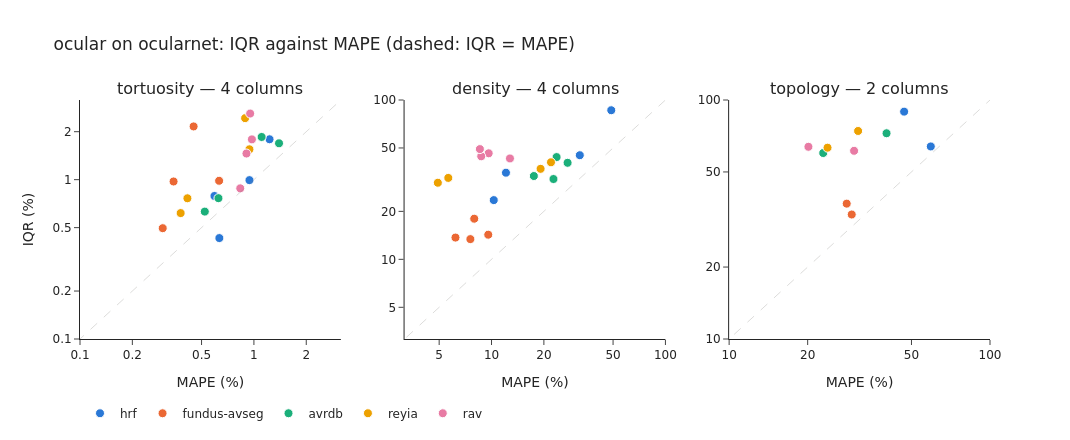

,tortuosity,density,topology
median IQR/MAPE · share > 1,,,
hrf,1.19 · 75%,2.03 · 100%,1.49 · 100%
fundus-avseg,2.24 · 100%,1.99 · 100%,1.21 · 100%
avrdb,1.22 · 100%,1.66 · 100%,2.21 · 100%
reyia,1.74 · 100%,3.84 · 100%,2.51 · 100%
rav,1.72 · 100%,4.94 · 100%,2.60 · 100%
pooled,1.75 · 100%,3.28 · 100%,2.63 · 100%


In [16]:
show_iqr_against_mape("ocular")

#### 3.2.2 automorph

[automorph](../docs/projects/automorph.md), on AutoMorph's artery/vein model.

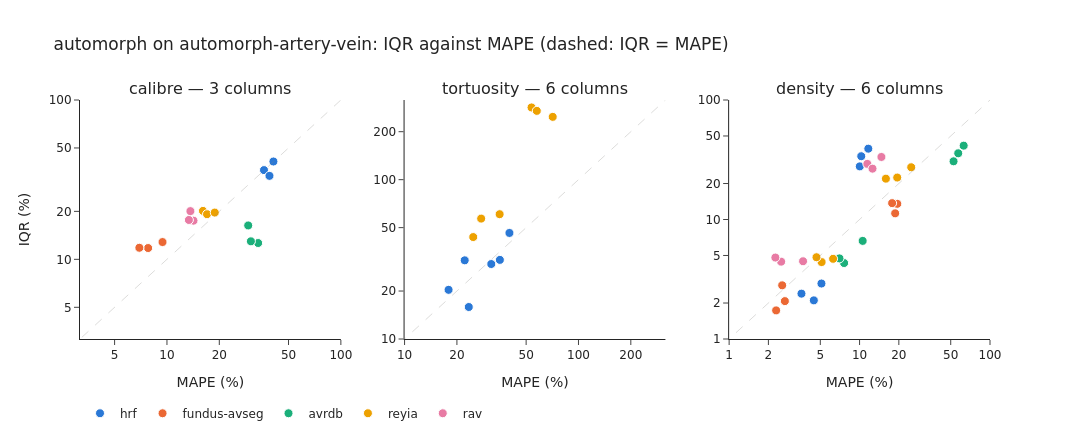

18 of 75 column × dataset pairs have an IQR or MAPE of 0, or none, and are not drawn


,calibre,tortuosity,density
median IQR/MAPE · share > 1,,,
hrf,1.00 · 67%,1.04 · 50%,1.72 · 50%
fundus-avseg,1.51 · 100%,0.00 · 0%,0.76 · 17%
avrdb,0.43 · 0%,0.00 · 0%,0.63 · 0%
reyia,1.13 · 100%,2.78 · 100%,1.07 · 67%
rav,1.32 · 100%,0.00 · 0%,2.12 · 100%
pooled,1.28 · 100%,4.34 · 100%,1.35 · 83%


In [17]:
show_iqr_against_mape("automorph")

#### 3.2.3 automorphalyzer

[automorphalyzer](../docs/projects/automorphalyzer.md), on AutoMorph's artery/vein model.

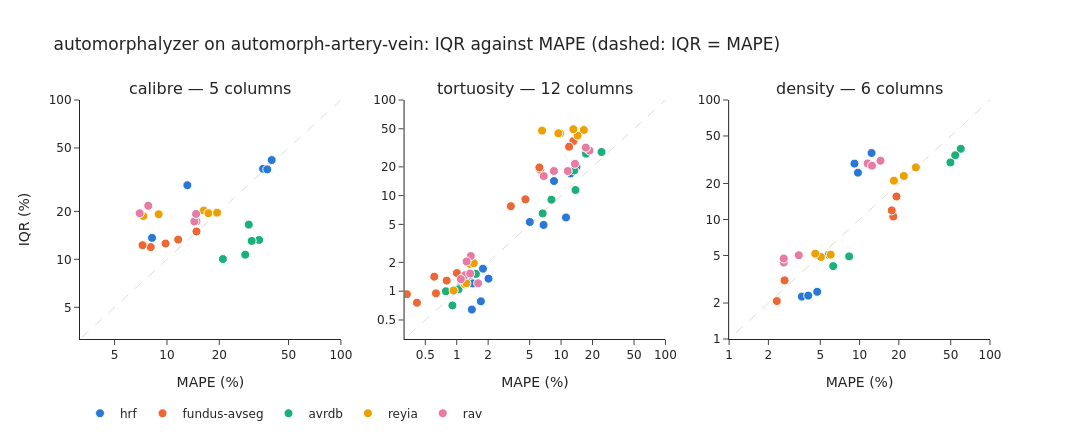

,calibre,tortuosity,density
median IQR/MAPE · share > 1,,,
hrf,1.05 · 80%,0.88 · 33%,1.58 · 50%
fundus-avseg,1.28 · 100%,2.34 · 100%,0.85 · 33%
avrdb,0.42 · 0%,1.04 · 67%,0.64 · 0%
reyia,1.24 · 100%,2.19 · 83%,1.03 · 67%
rav,1.31 · 100%,1.58 · 92%,1.97 · 100%
pooled,1.37 · 100%,2.57 · 92%,1.39 · 100%


In [18]:
show_iqr_against_mape("automorphalyzer")

#### 3.2.4 automorphclass

[automorphclass](../docs/projects/automorphclass.md), on AutoMorph's artery/vein model.

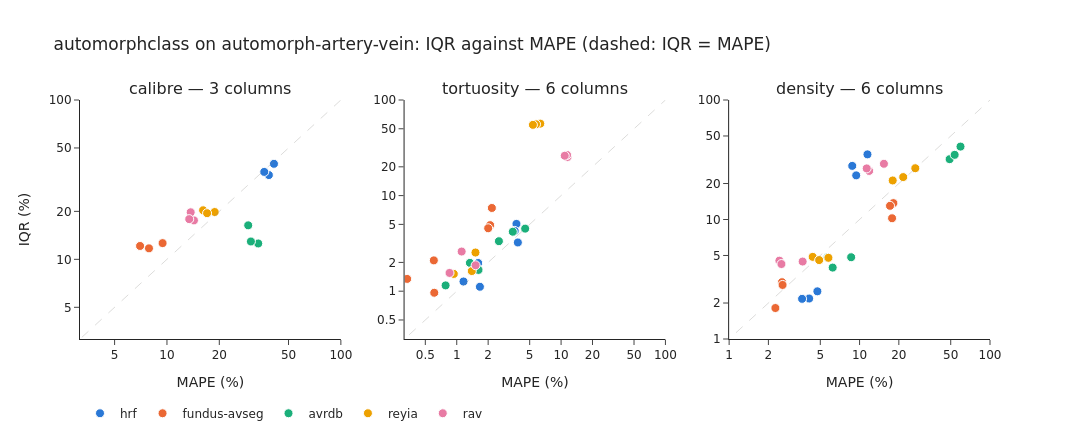

,calibre,tortuosity,density
median IQR/MAPE · share > 1,,,
hrf,0.96 · 0%,1.14 · 67%,1.54 · 50%
fundus-avseg,1.49 · 100%,2.88 · 100%,0.78 · 33%
avrdb,0.43 · 0%,1.27 · 83%,0.65 · 0%
reyia,1.14 · 100%,5.32 · 100%,1.03 · 67%
rav,1.33 · 100%,2.27 · 100%,1.88 · 100%
pooled,1.28 · 100%,5.19 · 100%,1.35 · 100%


In [19]:
show_iqr_against_mape("automorphclass")

#### 3.2.5 vascx

[vascx](../docs/projects/vascx.md), on VascX's artery/vein ensemble.

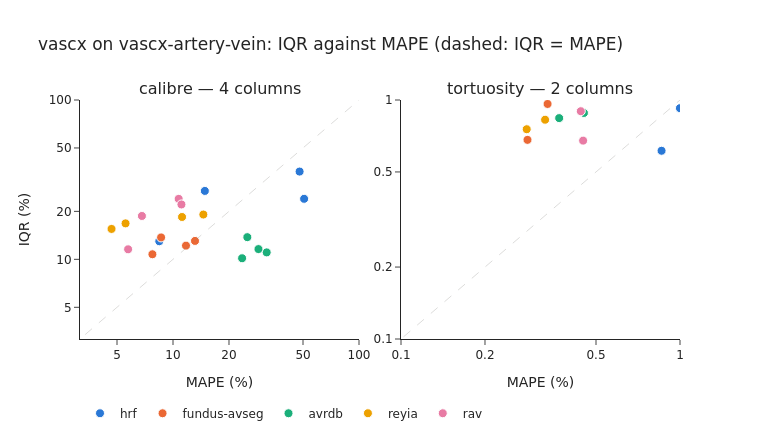

,calibre,tortuosity
median IQR/MAPE · share > 1,,
hrf,1.14 · 50%,0.82 · 0%
fundus-avseg,1.21 · 75%,2.63 · 100%
avrdb,0.42 · 0%,2.11 · 100%
reyia,2.34 · 100%,2.60 · 100%
rav,2.12 · 100%,1.77 · 100%
pooled,2.22 · 100%,2.56 · 100%


In [20]:
show_iqr_against_mape("vascx")

#### 3.2.6 fundus-biomarkers

[fundus-biomarkers](../docs/projects/fundus-biomarkers.md), on OCULARNet.

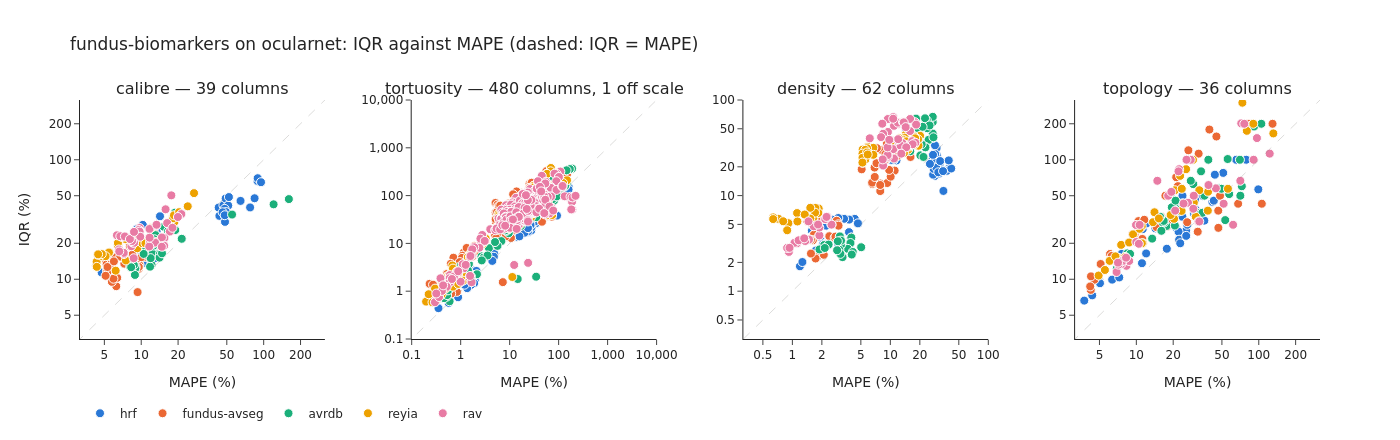

60 of 3145 column × dataset pairs have an IQR or MAPE of 0, or none, and are not drawn


,calibre,tortuosity,density,topology
median IQR/MAPE · share > 1,,,,
hrf,1.29 · 54%,1.60 · 89%,1.33 · 65%,1.41 · 83%
fundus-avseg,1.75 · 97%,3.15 · 99%,2.17 · 100%,2.08 · 86%
avrdb,1.41 · 92%,2.01 · 99%,1.48 · 74%,1.80 · 89%
reyia,1.97 · 100%,3.15 · 99%,3.94 · 100%,2.19 · 97%
rav,2.31 · 100%,2.76 · 96%,2.85 · 100%,1.79 · 83%
pooled,1.99 · 100%,2.84 · 99%,3.30 · 100%,2.11 · 94%


In [21]:
show_iqr_against_mape("fundus-biomarkers")

#### 3.2.7 Across the six

- **AVRDB is where calibre falls below the diagonal**, for every project but one: the median
  calibre IQR/MAPE there is 0.42–0.43 for the three AutoMorph projects and VascX, against 1.41 for
  fundus-biomarkers, whose model trained on AVRDB. On every other dataset each project's median
  calibre column is at or above 1, but for AutoMorphClass on HRF (0.96).
- **AutoMorph's tortuosity has an IQR of zero on three datasets.** On the expert's maps it returns
  exactly 1.0 — a perfectly straight vessel — for 78 of Fundus-AVSeg's 100 photographs, 90 of
  AVRDB's 99 and 182 of RAV's 198, against none of HRF's and 9 of REYIA's 554. With more than
  half the eyes at one value the IQR is 0, so IQR/MAPE is 0, and its ICC of 0.80 on Fundus-AVSeg
  rests on the few eyes that are not at 1.0 (section 2.3 shows the floor). AutoMorphalyzer and
  AutoMorphClass, on the same maps, do not do this. AutoMorph's
  [project page](../docs/projects/automorph.md) §8.1 records a tortuosity defect its successors
  fixed; whether this is that defect is not checked here.
- **HRF is where tortuosity is closest to the diagonal**: its median is below 1 for VascX (0.82)
  and AutoMorphalyzer (0.88). HRF's expert drew small vessels as hairlines (section 5).
- **The bands are the datasets and the kinds of measure**, as the introduction to this section
  explains: in fundus-biomarkers' density panel the fractal dimensions sit at an IQR of 2–8 % and
  the areas and lengths at 10–65 %, and within each band the datasets sit at different heights.

Nothing here ranks the projects: each project's dots are its own columns, measured its own way,
and a project with two tortuosity columns is not comparable dot for dot with one that has 480.

## 4. Where the programs disagree

### 4.1 One map, several programs

Two pairs of projects ship the same model: ocular and fundus-biomarkers both run OCULARNet, and
AutoMorph, AutoMorphalyzer and AutoMorphClass all run AutoMorph's artery/vein model. On those, the
maps are identical and only the program differs, so a biomarker robust in one program and fragile
in another is a finding about the program's tracing and measuring, not about the model. Every
column each program returns under a panel biomarker's stem, ICC(A,1) dataset by dataset.

In [22]:
STEMS = {label: "/".join(name.split("/")[:3]) for label, name in benchmark.PANEL}
SHARED = {}
for slug in PROJECTS:
    SHARED.setdefault(NATIVE[slug], []).append(slug)


def under_stem(slugs: list[str], stem: str) -> pd.DataFrame:
    rows = AGREE[AGREE["project"].isin(slugs) & AGREE["name"].fillna("").str.startswith(stem)]
    if rows.empty:
        return pd.DataFrame(columns=WITH_POOLED, index=pd.MultiIndex.from_tuples([], names=["project", "name"]))
    table = rows.pivot_table(index=["project", "name"], columns="dataset", values="icc_agreement", aggfunc="first")
    order = sorted(table.index, key=lambda key: (slugs.index(key[0]), key[1]))
    return table.reindex(index=order, columns=WITH_POOLED)


for model, slugs in SHARED.items():
    if len(slugs) < 2:
        continue
    for label, stem in STEMS.items():
        table = under_stem(slugs, stem)
        if table.index.get_level_values("project").nunique() >= 2:
            print(f"\n{label} on {model}'s maps — every program's column under {stem}, ICC(A,1)")
            display(shown(table))


Artery tortuosity on ocularnet's maps — every program's column under tortuosity/hart-tau1/artery, ICC(A,1)


dataset                                                           hrf  \
project           name                                                  
ocular            tortuosity/hart-tau1/artery/length-weighted    0.63   
                  tortuosity/hart-tau1/artery/median             0.63   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted  0.01   
                  tortuosity/hart-tau1/artery/B/mean             0.02   
                  tortuosity/hart-tau1/artery/B/median           0.33   
                  tortuosity/hart-tau1/artery/B/std             -0.02   
                  tortuosity/hart-tau1/artery/C/length-weighted  0.14   
                  tortuosity/hart-tau1/artery/C/mean             0.18   
                  tortuosity/hart-tau1/artery/C/median           0.73   
                  tortuosity/hart-tau1/artery/C/std              0.04   
                  tortuosity/hart-tau1/artery/length-weighted    0.14   
                  tortuosity/hart-tau1/artery/mean               0.13   
                  tortuosity/hart-tau1/artery/median             0.79   
                  tortuosity/hart-tau1/artery/std                0.02   

dataset                                                         fundus-avseg  \
project           name                                                         
ocular            tortuosity/hart-tau1/artery/length-weighted           0.97   
                  tortuosity/hart-tau1/artery/median                     0.9   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted         0.91   
                  tortuosity/hart-tau1/artery/B/mean                    0.89   
                  tortuosity/hart-tau1/artery/B/median                  0.95   
                  tortuosity/hart-tau1/artery/B/std                     0.81   
                  tortuosity/hart-tau1/artery/C/length-weighted         0.95   
                  tortuosity/hart-tau1/artery/C/mean                    0.94   
                  tortuosity/hart-tau1/artery/C/median                  0.94   
                  tortuosity/hart-tau1/artery/C/std                      0.8   
                  tortuosity/hart-tau1/artery/length-weighted           0.68   
                  tortuosity/hart-tau1/artery/mean                      0.86   
                  tortuosity/hart-tau1/artery/median                    0.92   
                  tortuosity/hart-tau1/artery/std                       0.21   

dataset                                                         avrdb reyia  \
project           name                                                        
ocular            tortuosity/hart-tau1/artery/length-weighted    0.62  0.77   
                  tortuosity/hart-tau1/artery/median             0.47  0.72   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted  0.78  0.37   
                  tortuosity/hart-tau1/artery/B/mean             0.75  0.47   
                  tortuosity/hart-tau1/artery/B/median           0.48  0.89   
                  tortuosity/hart-tau1/artery/B/std              0.52  0.12   
                  tortuosity/hart-tau1/artery/C/length-weighted  0.61  0.72   
                  tortuosity/hart-tau1/artery/C/mean             0.61  0.73   
                  tortuosity/hart-tau1/artery/C/median           0.77  0.86   
                  tortuosity/hart-tau1/artery/C/std              0.24   0.2   
                  tortuosity/hart-tau1/artery/length-weighted    0.33  0.71   
                  tortuosity/hart-tau1/artery/mean               0.26  0.75   
                  tortuosity/hart-tau1/artery/median             0.81  0.86   
                  tortuosity/hart-tau1/artery/std                0.03  0.56   

dataset                                                           rav pooled  
project           name                                                        
ocular            tortuosity/hart-tau1/artery/length-weighted    0.87   0.81  
                  tortuosity/hart-tau1/artery/me


Artery fractal dimension on automorph-artery-vein's maps — every program's column under density/box-counting/artery, ICC(A,1)


,dataset,hrf,fundus-avseg,avrdb,reyia,rav,pooled
project,name,,,,,,
automorph,density/box-counting/artery,0.25,0.47,0.22,0.36,0.46,0.37
automorphalyzer,density/box-counting/artery,0.19,0.55,0.2,0.4,0.6,0.57
automorphclass,density/box-counting/artery,0.17,0.55,0.16,0.37,0.45,0.52



Artery tortuosity on automorph-artery-vein's maps — every program's column under tortuosity/hart-tau1/artery, ICC(A,1)


dataset                                                       hrf  \
project         name                                                
automorph       tortuosity/hart-tau1/artery/mean             0.05   
automorphalyzer tortuosity/hart-tau1/artery/B/mean           0.31   
                tortuosity/hart-tau1/artery/mean             0.12   
automorphclass  tortuosity/hart-tau1/artery/length-weighted  0.23   

dataset                                                     fundus-avseg  \
project         name                                                       
automorph       tortuosity/hart-tau1/artery/mean                     0.8   
automorphalyzer tortuosity/hart-tau1/artery/B/mean                  0.43   
                tortuosity/hart-tau1/artery/mean                    0.84   
automorphclass  tortuosity/hart-tau1/artery/length-weighted         0.94   

dataset                                                     avrdb reyia   rav  \
project         name                                                            
automorph       tortuosity/hart-tau1/artery/mean              0.0  0.24 -0.06   
automorphalyzer tortuosity/hart-tau1/artery/B/mean           0.14  0.36   0.7   
                tortuosity/hart-tau1/artery/mean             0.35  0.32  0.62   
automorphclass  tortuosity/hart-tau1/artery/length-weighted   0.3  0.39  0.78   

dataset                                                     pooled  
project         name                                                
automorph       tortuosity/hart-tau1/artery/mean              0.37  
automorphalyzer tortuosity/hart-tau1/artery/B/mean            0.44  
                tortuosity/hart-tau1/artery/mean              0.41  
automorphclass  tortuosity/hart-tau1/artery/length-weighted    0.5

**Reading it.** On OCULARNet's maps, ocular's median artery tortuosity agrees at 0.47 on AVRDB and
0.66 on RAV, where fundus-biomarkers' median of the same maps agrees at 0.81 and 0.92: the
difference is the program's tracing. On AutoMorph's maps, the three programs' fractal dimensions
are within 0.15 of one another on every dataset, but their tortuosities are not: AutoMorph's mean
is −0.06 on RAV where AutoMorphalyzer's mean is 0.62 and AutoMorphClass's length-weighted mean
0.78 — the straight-vessel values of section 3.2.7 are AutoMorph's own.

### 4.2 One biomarker, every project on its own model

The end-to-end comparison: each project's own column under a panel biomarker's stem, on its own
model's maps, ICC(A,1) dataset by dataset. Here the model and the program differ together, as they
do for a study that adopts a project whole. It cannot say which of the two made the difference;
section 4.1 can, where two programs share a model.

In [23]:
for label, stem in STEMS.items():
    table = under_stem(PROJECTS, stem)
    if len(table):
        print(f"\n{label} — every project's column under {stem}, on its own model, ICC(A,1)")
        display(shown(table))


CRAE — every project's column under calibre/CRE-knudtson/artery, on its own model, ICC(A,1)


dataset                                           hrf fundus-avseg avrdb  \
project           name                                                     
automorphalyzer   calibre/CRE-knudtson/artery/B  0.47         0.32  0.06   
vascx             calibre/CRE-knudtson/artery/B  0.54         0.38  0.02   
fundus-biomarkers calibre/CRE-knudtson/artery/B  0.61          0.6  0.39   
                  calibre/CRE-knudtson/artery/C   0.6          0.6  0.44   

dataset                                         reyia   rav pooled  
project           name                                              
automorphalyzer   calibre/CRE-knudtson/artery/B  0.69   0.8   0.57  
vascx             calibre/CRE-knudtson/artery/B  0.81   0.8   0.56  
fundus-biomarkers calibre/CRE-knudtson/artery/B  0.86  0.78   0.83  
                  calibre/CRE-knudtson/artery/C  0.86  0.76   0.83


CRVE — every project's column under calibre/CRE-knudtson/vein, on its own model, ICC(A,1)


dataset                                         hrf fundus-avseg avrdb reyia  \
project           name                                                         
automorphalyzer   calibre/CRE-knudtson/vein/B  0.53         0.48   0.1  0.75   
vascx             calibre/CRE-knudtson/vein/B  0.42         0.56  0.06  0.84   
fundus-biomarkers calibre/CRE-knudtson/vein/B  0.39         0.72  0.51  0.86   
                  calibre/CRE-knudtson/vein/C  0.44         0.74  0.62  0.87   

dataset                                         rav pooled  
project           name                                      
automorphalyzer   calibre/CRE-knudtson/vein/B  0.83   0.63  
vascx             calibre/CRE-knudtson/vein/B   0.8   0.63  
fundus-biomarkers calibre/CRE-knudtson/vein/B  0.86   0.87  
                  calibre/CRE-knudtson/vein/C  0.85   0.87


AVR — every project's column under calibre/AVR-knudtson/both, on its own model, ICC(A,1)


dataset                                         hrf fundus-avseg avrdb reyia  \
project           name                                                         
fundus-biomarkers calibre/AVR-knudtson/both/B  0.68         0.78  0.41  0.81   
                  calibre/AVR-knudtson/both/C  0.69          0.8  0.33  0.81   

dataset                                         rav pooled  
project           name                                      
fundus-biomarkers calibre/AVR-knudtson/both/B  0.66   0.73  
                  calibre/AVR-knudtson/both/C  0.73   0.74


Artery fractal dimension — every project's column under density/box-counting/artery, on its own model, ICC(A,1)


dataset                                           hrf fundus-avseg avrdb  \
project           name                                                     
automorph         density/box-counting/artery    0.25         0.47  0.22   
automorphalyzer   density/box-counting/artery    0.19         0.55   0.2   
automorphclass    density/box-counting/artery    0.17         0.55  0.16   
fundus-biomarkers density/box-counting/artery    0.35         0.66  0.13   
                  density/box-counting/artery/B  0.31         0.75  0.26   
                  density/box-counting/artery/C   0.2         0.71  0.32   

dataset                                         reyia   rav pooled  
project           name                                              
automorph         density/box-counting/artery    0.36  0.46   0.37  
automorphalyzer   density/box-counting/artery     0.4   0.6   0.57  
automorphclass    density/box-counting/artery    0.37  0.45   0.52  
fundus-biomarkers density/box-counting/artery    0.95  0.75    0.8  
                  density/box-counting/artery/B  0.89  0.75   0.81  
                  density/box-counting/artery/C  0.89  0.72   0.81


Artery tortuosity — every project's column under tortuosity/hart-tau1/artery, on its own model, ICC(A,1)


dataset                                                           hrf  \
project           name                                                  
ocular            tortuosity/hart-tau1/artery/length-weighted    0.63   
                  tortuosity/hart-tau1/artery/median             0.63   
automorph         tortuosity/hart-tau1/artery/mean               0.05   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean             0.31   
                  tortuosity/hart-tau1/artery/mean               0.12   
automorphclass    tortuosity/hart-tau1/artery/length-weighted    0.23   
vascx             tortuosity/hart-tau1/artery/length-weighted    0.39   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted  0.01   
                  tortuosity/hart-tau1/artery/B/mean             0.02   
                  tortuosity/hart-tau1/artery/B/median           0.33   
                  tortuosity/hart-tau1/artery/B/std             -0.02   
                  tortuosity/hart-tau1/artery/C/length-weighted  0.14   
                  tortuosity/hart-tau1/artery/C/mean             0.18   
                  tortuosity/hart-tau1/artery/C/median           0.73   
                  tortuosity/hart-tau1/artery/C/std              0.04   
                  tortuosity/hart-tau1/artery/length-weighted    0.14   
                  tortuosity/hart-tau1/artery/mean               0.13   
                  tortuosity/hart-tau1/artery/median             0.79   
                  tortuosity/hart-tau1/artery/std                0.02   

dataset                                                         fundus-avseg  \
project           name                                                         
ocular            tortuosity/hart-tau1/artery/length-weighted           0.97   
                  tortuosity/hart-tau1/artery/median                     0.9   
automorph         tortuosity/hart-tau1/artery/mean                       0.8   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean                    0.43   
                  tortuosity/hart-tau1/artery/mean                      0.84   
automorphclass    tortuosity/hart-tau1/artery/length-weighted           0.94   
vascx             tortuosity/hart-tau1/artery/length-weighted           0.88   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted         0.91   
                  tortuosity/hart-tau1/artery/B/mean                    0.89   
                  tortuosity/hart-tau1/artery/B/median                  0.95   
                  tortuosity/hart-tau1/artery/B/std                     0.81   
                  tortuosity/hart-tau1/artery/C/length-weighted         0.95   
                  tortuosity/hart-tau1/artery/C/mean                    0.94   
                  tortuosity/hart-tau1/artery/C/median                  0.94   
                  tortuosity/hart-tau1/artery/C/std                      0.8   
                  tortuosity/hart-tau1/artery/length-weighted           0.68   
                  tortuosity/hart-tau1/artery/mean                      0.86   
                  tortuosity/hart-tau1/artery/median                    0.92   
                  tortuosity/hart-tau1/artery/std                       0.21   

dataset                                                         avrdb reyia  \
project           name                                                        
ocular            tortuosity/hart-tau1/artery/length-weighted    0.62  0.77   
                  tortuosity/hart-tau1/artery/median             0.47  0.72   
automorph         tortuosity/hart-tau1/artery/mean                0.0  0.24   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean             0.14  0.36   
                  tortuosity/hart-tau1/artery/mean               0.35  0.32   
automorphclass    tortuosity/hart-tau1/artery/length-weighted     0.3  0.39   
vascx             tortuosity/hart-tau1/artery/length-weighted    0.52   0.7   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted  0.78  0.3

**Reading it.** fundus-biomarkers on OCULARNet agrees best on most panel biomarkers and datasets,
and its model trained on four of the five datasets (section 7.1). The exceptions are HRF's CRVE
(0.39, against AutoMorphalyzer's 0.53 and VascX's 0.42) and AVRDB's fractal dimension (0.13,
against 0.16–0.22 for the AutoMorph programs). On RAV — out of sample
for OCULARNet and AutoMorph's model, in sample for VascX's — CRAE is 0.78 (fundus-biomarkers),
0.80 (AutoMorphalyzer) and 0.80 (VascX): within 0.02. Section 7.5 makes that comparison on the
held-out photographs alone.

## 5. What the hard cases look like

For each project, and within it each dataset, the photograph where its own model's map moved the
project's first panel biomarker furthest from the expert's value, relative to that value. Shown
left to right: the photograph, the expert's map, the model's map. Arteries are red and veins blue.
The three AutoMorph-family projects and the two OCULARNet ones share maps, so a photograph can
recur among them.

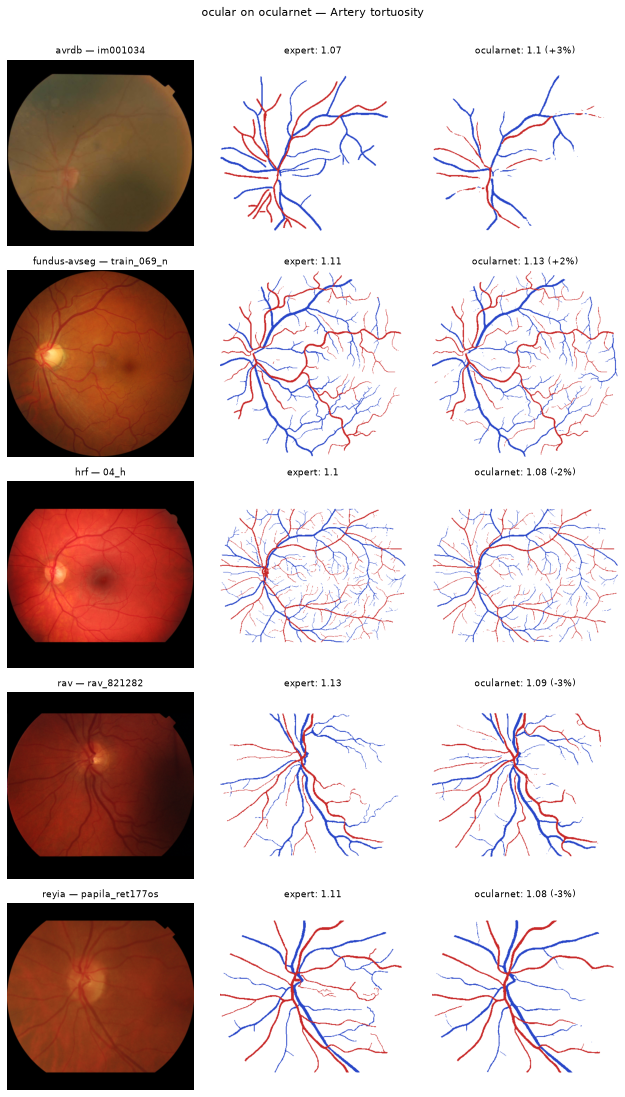

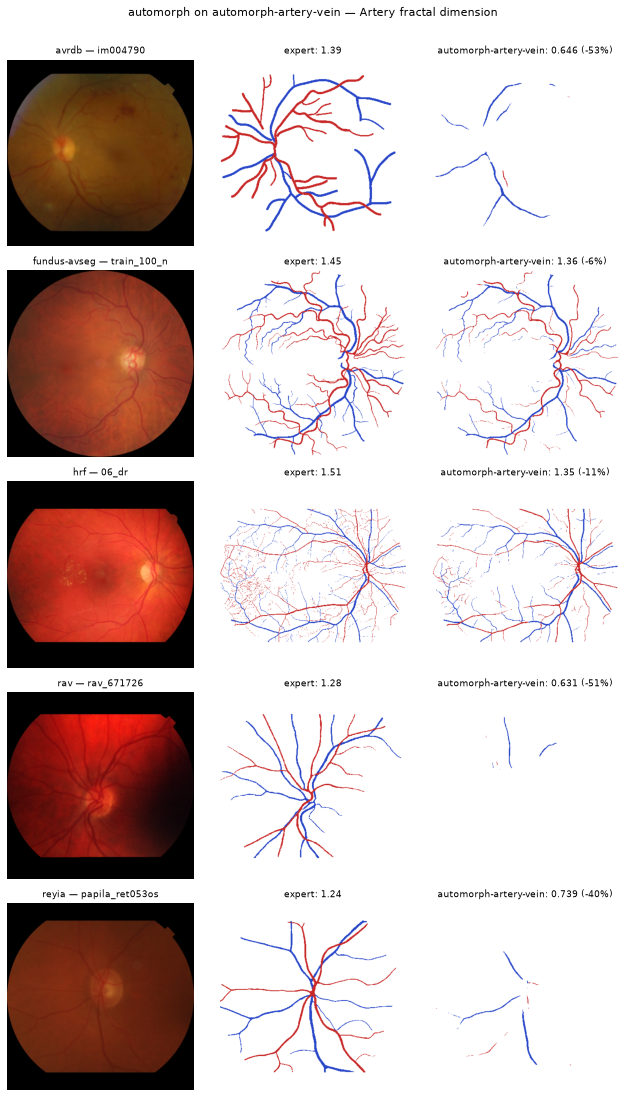

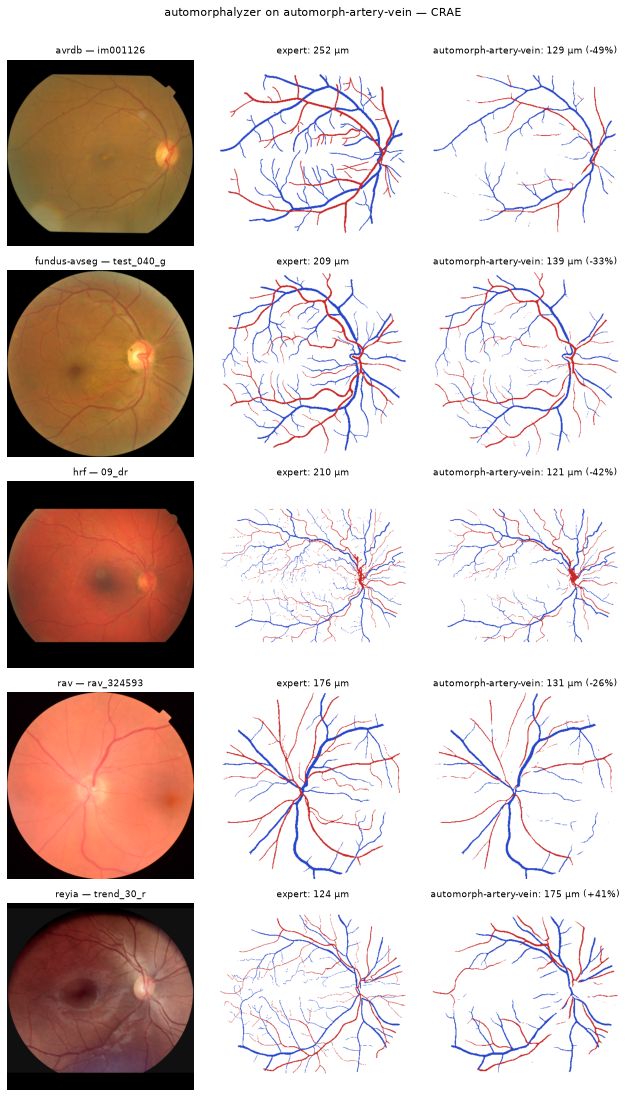

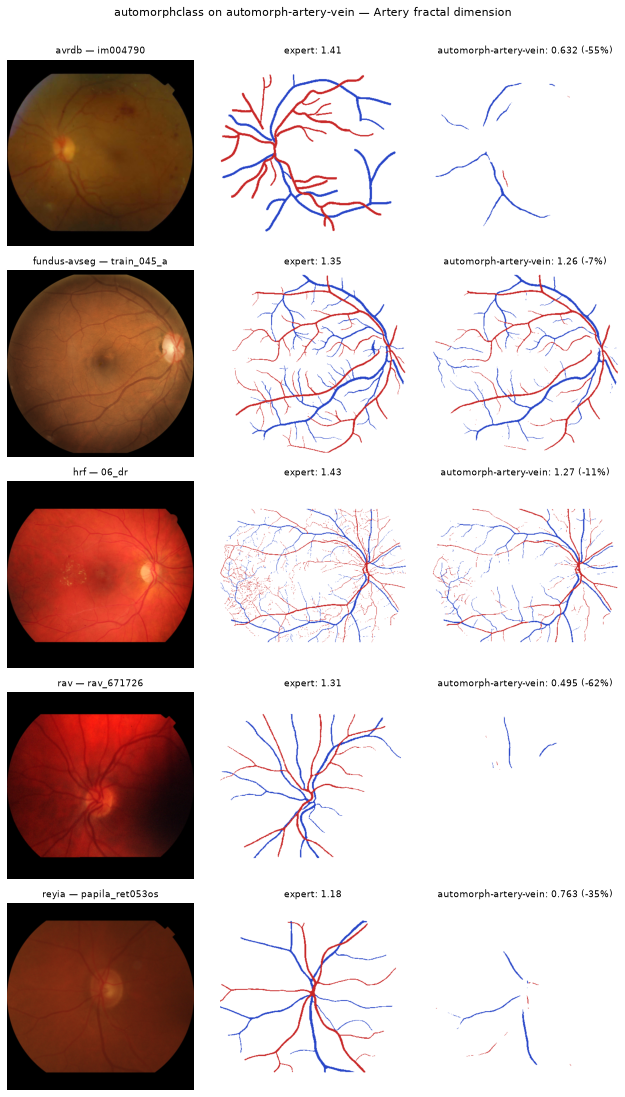

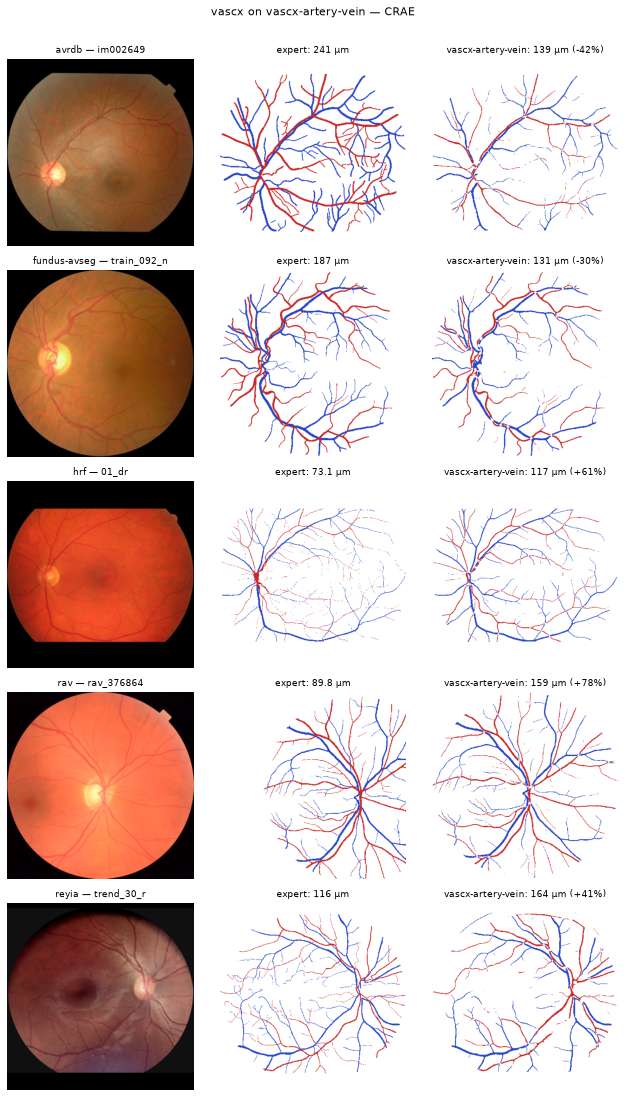

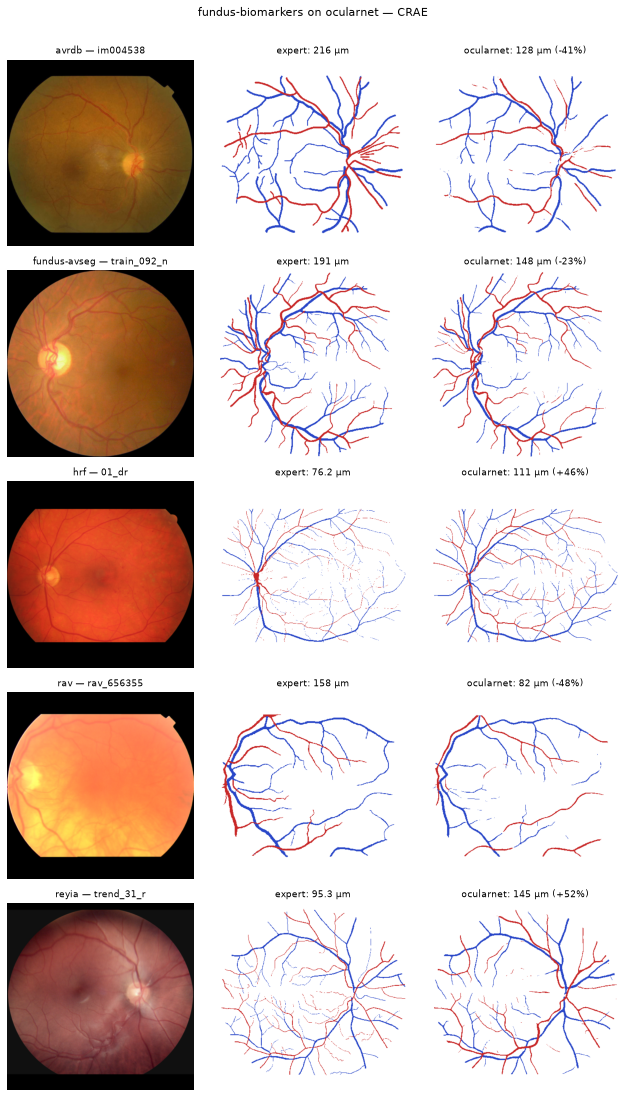

In [24]:
def painted(artery: np.ndarray, vein: np.ndarray) -> np.ndarray:
    canvas = np.full((*artery.shape, 3), 255, dtype=np.uint8)
    canvas[vein] = (40, 70, 200)
    canvas[artery] = (200, 40, 40)
    return canvas


def small(path: Path, side: int = 420, rgb: bool = False) -> np.ndarray:
    """A picture shrunk for the page: HRF's crops are 3,300 pixels across."""
    picture = Image.open(path).convert("RGB" if rgb else "L")
    picture.thumbnail((side, side), Image.Resampling.BILINEAR if rgb else Image.Resampling.NEAREST)
    return np.asarray(picture) if rgb else np.asarray(picture) > 0


for slug in PROJECTS:
    label = next(label for label in LABELS if label in PANELS[slug])
    pairs = PAIRS[(slug, label)].assign(moved=lambda f: (f["said"] - f["expert"]) / f["expert"].abs())
    worst = pairs.loc[pairs.groupby("dataset")["moved"].apply(lambda s: s.abs().idxmax())]
    unit = canonical.unit(PANELS[slug][label])
    unit = "" if unit == "1" else f" {unit}"
    figure, axes = plt.subplots(len(worst), 3, figsize=(9, 3.1 * len(worst)), squeeze=False, dpi=72)
    for row, (_, case) in enumerate(worst.iterrows()):
        crop = STORE / case["dataset"] / "crop"
        kept = KEPT / NATIVE[slug] / case["dataset"]
        for column, (title, picture) in enumerate((
            (f"{case['dataset']} — {case['key']}", small(crop / "images" / f"{case['key']}.png", rgb=True)),
            (f"expert: {case['expert']:.3g}{unit}",
             painted(small(crop / "artery" / f"{case['key']}.png"), small(crop / "vein" / f"{case['key']}.png"))),
            (f"{NATIVE[slug]}: {case['said']:.3g}{unit} ({100 * case['moved']:+.0f}%)",
             painted(small(kept / f"{case['key']}-artery.png"), small(kept / f"{case['key']}-vein.png"))),
        )):
            axes[row, column].imshow(picture)
            axes[row, column].set_title(title, fontsize=9)
            axes[row, column].axis("off")
    figure.suptitle(f"{slug} on {NATIVE[slug]} — {label}{variant(slug, label)}", fontsize=11)
    figure.tight_layout(rect=(0, 0, 1, 0.975))
    plt.show()

## 6. What it costs

Two costs, project by project and dataset by dataset: **the program's seconds per map**, averaged
over the expert's and its own model's maps, on one core of this machine; and **its own model's
seconds per photograph**, from the artery/vein benchmark, on the device named beside it. Both
measure the machine as much as the software.

In [25]:
rows = []
for slug in PROJECTS:
    for dataset in DATASETS:
        found = evidence(slug, dataset)
        seconds = [float(row["seconds"]) for row in found if row.get("seconds")]
        drawn = AV_RESULTS / NATIVE[slug] / f"{dataset}.json"
        model = json.loads(drawn.read_text())["summary"] if drawn.exists() else {}
        rows.append({"project": slug, "dataset": dataset,
                     "program, seconds per map": np.mean(seconds) if seconds else np.nan,
                     "own model, seconds per photograph": model.get("seconds_per_photograph", np.nan),
                     "model measured on": model.get("device", "—")})
costs = pd.DataFrame(rows).set_index(["project", "dataset"])
numeric = costs.columns[:2]
costs[numeric] = shown(costs[numeric], 1)
costs

program, seconds per map  \
project           dataset                                 
ocular            hrf                              28.6   
                  fundus-avseg                      6.6   
                  avrdb                             3.4   
                  reyia                             8.0   
                  rav                               3.1   
automorph         hrf                              12.6   
                  fundus-avseg                      9.7   
                  avrdb                            11.0   
                  reyia                             6.4   
                  rav                              10.9   
automorphalyzer   hrf                              82.0   
                  fundus-avseg                     15.3   
                  avrdb                             6.4   
                  reyia                            23.1   
                  rav                               6.6   
automorphclass    hrf                               7.1   
                  fundus-avseg                      1.1   
                  avrdb                             0.6   
                  reyia                             1.3   
                  rav                               0.5   
vascx             hrf                              35.1   
                  fundus-avseg                      7.8   
                  avrdb                             3.8   
                  reyia                             7.9   
                  rav                               3.1   
fundus-biomarkers hrf                              84.6   
                  fundus-avseg                     18.4   
                  avrdb                             8.5   
                  reyia                            14.5   
                  rav                               5.9   

                               own model, seconds per photograph  \
project           dataset                                          
ocular            hrf                                        2.5   
                  fundus-avseg                               2.9   
                  avrdb                                      2.4   
                  reyia                                      9.0   
                  rav                                        3.4   
automorph         hrf                                        3.9   
                  fundus-avseg                               4.1   
                  avrdb                                      4.4   
                  reyia                                     12.4   
                  rav                                       11.0   
automorphalyzer   hrf                                        3.9   
                  fundus-avseg                               4.1   
                  avrdb                                      4.4   
                  reyia                                     12.4   
                  rav                                       11.0   
automorphclass    hrf                                        3.9   
                  fundus-avseg                               4.1   
                  avrdb                                      4.4   
                  reyia                                     12.4   
                  rav                                       11.0   
vascx             hrf                                        9.4   
                  fundus-avseg                              18.6   
                  avrdb                                      8.9   
                  reyia                                     12.7   
                  rav                                       22.8   
fundus-biomarkers hrf                                        2.5   
                  fundus-avseg                               2.9   
                  avrdb                                      2.4   
                  reyia                                      9.0   
                  rav             

## 7. What the benchmark cannot say

### 7.1 Contamination

A model trained on a dataset's own annotations has seen these expert maps. Its ICC there measures
how well it reproduces its training labels, not how it would fare on a new cohort. The marks are
the run's own, for each project's own model, dataset by dataset.

In [26]:
marks = PER_DATASET.drop_duplicates(["project", "dataset"]).pivot(
    index="project", columns="dataset", values="contamination").reindex(index=PROJECTS, columns=DATASETS)
marks.insert(0, "model", [NATIVE[s] for s in marks.index])
marks

dataset,model,hrf,fundus-avseg,avrdb,reyia,rav
project,,,,,,
ocular,ocularnet,in-sample-unclear-split,in-sample-unclear-split,in-sample-unclear-split,"mixed: in-sample, out-of-sample",out-of-sample
automorph,automorph-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,out-of-sample
automorphalyzer,automorph-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,out-of-sample
automorphclass,automorph-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,out-of-sample
vascx,vascx-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,in-sample-unclear-split
fundus-biomarkers,ocularnet,in-sample-unclear-split,in-sample-unclear-split,in-sample-unclear-split,"mixed: in-sample, out-of-sample",out-of-sample


### 7.2 Out-of-sample only

Each project's panel ICC(A,1) over the datasets where its own model is marked `out-of-sample`, set
beside its pooled figure. A grouping the run does not make, so it is computed here by the run's own
function, over the same pairs.

In [27]:
clean = {}
for (slug, label), pairs in PAIRS.items():
    out = [d for d in DATASETS if marks.loc[slug, d] == "out-of-sample"]
    mine = pairs[pairs["dataset"].isin(out)]
    found = agreement.summary(list(mine["expert"]), list(mine["said"]))
    clean[(slug, label)] = {"ICC(A,1) out-of-sample": found.get("icc_agreement"), "n": found["n"],
                            "datasets": ", ".join(out) or "—",
                            "ICC(A,1) pooled": pooled_panel.loc[slug, ("ICC(A,1)", label)]}
clean = pd.DataFrame(clean).T.rename_axis(["project", "biomarker"])
shown(clean.drop(columns="datasets")).join(clean["datasets"])

ICC(A,1) out-of-sample      n  \
project           biomarker                                                
ocular            Artery tortuosity                          0.66  198.0   
automorph         Artery fractal dimension                   0.37  948.0   
                  Artery tortuosity                          0.38  948.0   
automorphalyzer   CRAE                                       0.57  756.0   
                  CRVE                                       0.63  805.0   
                  Artery fractal dimension                   0.57  945.0   
                  Artery tortuosity                          0.44  945.0   
automorphclass    Artery fractal dimension                   0.53  948.0   
                  Artery tortuosity                          0.51  948.0   
vascx             CRAE                                       0.54  557.0   
                  CRVE                                       0.62  574.0   
                  Artery tortuosity                          0.73  608.0   
fundus-biomarkers CRAE                                       0.78  155.0   
                  CRVE                                       0.86  155.0   
                  AVR                                        0.66  155.0   
                  Artery fractal dimension                   0.75  155.0   
                  Artery tortuosity                          0.92  155.0   

                                           ICC(A,1) pooled  \
project           biomarker                                  
ocular            Artery tortuosity                   0.72   
automorph         Artery fractal dimension            0.37   
                  Artery tortuosity                   0.37   
automorphalyzer   CRAE                                0.57   
                  CRVE                                0.63   
                  Artery fractal dimension            0.57   
                  Artery tortuosity                   0.41   
automorphclass    Artery fractal dimension            0.52   
                  Artery tortuosity                    0.5   
vascx             CRAE                                0.56   
                  CRVE                                0.63   
                  Artery tortuosity                   0.71   
fundus-biomarkers CRAE                                0.83   
                  CRVE                                0.87   
                  AVR                                 0.73   
                  Artery fractal dimension             0.8   
                  Artery tortuosity                   0.88   

                                                                   datasets  
project           biomarker                                                  
ocular            Artery tortuosity                                     rav  
automorph         Artery fractal dimension  fundus-avseg, avrdb, reyia, rav  
                  Artery tortuosity         fundus-avseg, avrdb, reyia, rav  
automorphalyzer   CRAE                      fundus-avseg, avrdb, reyia, rav  
                  CRVE                      fundus-avseg, avrdb, reyia, rav  
                  Artery fractal dimension  fundus-avseg, avrdb, reyia, rav  
                  Artery tortuosity         fundus-avseg, avrdb, reyia, rav  
automorphclass    Artery fractal dimension  fundus-avseg, avrdb, reyia, rav  
                  Artery tortuosity         fundus-avseg, avrdb, reyia, rav  
vascx             CRAE                           fundus-avseg, avrdb, reyia  
                  CRVE                           fundus-avseg, avrdb, reyia  
                  Artery tortuosity              fundus-avseg, avrdb, reyia  
fundus-biomarkers CRAE                                                  rav  
                  CRVE                                                  rav  
                  AVR                                                   rav  
                  Artery fractal dimension                              rav  
               

### 7.3 REYIA by subset

REYIA is a compilation of collections from different cameras and clinics. The panel ICC(A,1) per
subset, project by project, shows whether one collection drives the dataset's figure.

In [28]:
subsets = {}
for (slug, label), pairs in PAIRS.items():
    for subset, group in pairs[pairs["dataset"] == "reyia"].groupby("subset"):
        found = agreement.summary(list(group["expert"]), list(group["said"]))
        subsets[(slug, subset, label)] = found.get("icc_agreement")
subset_table = pd.Series(subsets, dtype=float).unstack(-1).reindex(columns=LABELS)
subset_table = subset_table.reindex(PROJECTS, level=0).rename_axis(["project", "subset"])
display(shown(subset_table.dropna(how="all", axis=1)))

CRAE  CRVE   AVR Artery fractal dimension  \
project           subset                                                
ocular            enrich       —     —     —                        —   
                  fives        —     —     —                        —   
                  grape        —     —     —                        —   
                  magreb       —     —     —                        —   
                  mbrset       —     —     —                        —   
                  messidor     —     —     —                        —   
                  papila       —     —     —                        —   
                  trend        —     —     —                        —   
automorph         enrich       —     —     —                     0.32   
                  fives        —     —     —                     0.28   
                  grape        —     —     —                     0.28   
                  magreb       —     —     —                     0.54   
                  mbrset       —     —     —                     0.29   
                  messidor     —     —     —                     0.29   
                  papila       —     —     —                      0.2   
                  trend        —     —     —                     0.14   
automorphalyzer   enrich    0.86  0.74     —                     0.31   
                  fives     0.82  0.78     —                     0.28   
                  grape     0.67  0.82     —                      0.3   
                  magreb       —     —     —                     0.53   
                  mbrset     0.7  0.71     —                     0.26   
                  messidor  0.73  0.87     —                     0.28   
                  papila    0.43  0.45     —                     0.22   
                  trend     0.54  0.76     —                      0.1   
automorphclass    enrich       —     —     —                     0.29   
                  fives        —     —     —                     0.27   
                  grape        —     —     —                     0.28   
                  magreb       —     —     —                     0.52   
                  mbrset       —     —     —                     0.21   
                  messidor     —     —     —                     0.28   
                  papila       —     —     —                     0.23   
                  trend        —     —     —                     0.08   
vascx             enrich    0.92  0.91     —                        —   
                  fives     0.92  0.92     —                        —   
                  grape     0.87  0.94     —                        —   
                  magreb       —     —     —                        —   
                  mbrset    0.76  0.74     —                        —   
                  messidor  0.89   0.9     —                        —   
                  papila    0.63   0.7     —                        —   
                  trend     0.65  0.66     —                        —   
fundus-biomarkers enrich    0.94  0.97  0.89                     0.83   
                  fives     0.89  0.93  0.92                     0.76   
                  grape     0.91  0.94   0.9                      0.8   
                  mbrset    0.69  0.85   0.3                     0.66   
                  messidor  0.82  0.91  0.95                     0.78   
                  papila    0.88  0.86  0.75                     0.89   
                  trend     0.58  0.48  0.41                     0.47   

                           Artery tortuosity  
project           subset                      
ocular            enrich                0.66  
                  fives                 0.82  
                  grape                 0.65  
                  magreb                0.68  
                  mbrset                0.68  
                  messidor              0.87  
                  papila                0.73  
                  trend    

### 7.4 Without AVRDB

AVRDB's expert maps are drawn with strokes about 1.6 times wider than the vessels any model traces
(the [artery/vein results](../docs/benchmarks/av-results.md) §4.1), and its points sit off the
diagonal in section 2.3. Its rows measure how closely a model reproduces a wide-stroke drawing. It
stays in every pooled figure above; this table shows how much it moves them. A grouping the run
does not make, computed by the run's own function over the same pairs.

In [29]:
without = {}
for (slug, label), pairs in PAIRS.items():
    mine = pairs[pairs["dataset"] != "avrdb"]
    without[(slug, label)] = agreement.summary(list(mine["expert"]), list(mine["said"])).get("icc_agreement")
without = pd.Series(without, dtype=float).unstack().reindex(index=PROJECTS, columns=LABELS)
shown(pd.concat({"ICC(A,1) without AVRDB": without, "ICC(A,1) pooled": pooled_panel["ICC(A,1)"]}, axis=1))

ICC(A,1) without AVRDB                                       \
                                    CRAE  CRVE   AVR Artery fractal dimension   
ocular                                 —     —     —                        —   
automorph                              —     —     —                     0.43   
automorphalyzer                     0.66  0.74     —                     0.63   
automorphclass                         —     —     —                      0.6   
vascx                               0.74  0.81     —                        —   
fundus-biomarkers                   0.81  0.85  0.76                     0.91   

                                    ICC(A,1) pooled              \
                  Artery tortuosity            CRAE  CRVE   AVR   
ocular                         0.74               —     —     —   
automorph                      0.36               —     —     —   
automorphalyzer                0.41            0.57  0.63     —   
automorphclass                 0.52               —     —     —   
vascx                          0.72            0.56  0.63     —   
fundus-biomarkers              0.89            0.83  0.87  0.73   

                                                              
                  Artery fractal dimension Artery tortuosity  
ocular                                   —              0.72  
automorph                             0.37              0.37  
automorphalyzer                       0.57              0.41  
automorphclass                        0.52               0.5  
vascx                                    —              0.71  
fundus-biomarkers                      0.8              0.88

### 7.5 On the photographs OCULARNet did not train on

OCULARNet — the model ocular and fundus-biomarkers both run — trained on four of these five
datasets and six of REYIA's eight subsets, so most of their figures above are in-sample. REYIA's
mBRSET and TREND-AV subsets, and RAV, are the photographs it never saw. Every project on its own
model over the same held-out photographs, so the comparison is like for like. VascX's model is
in-sample on RAV.

In [30]:
held_out = {}
for (slug, label), pairs in PAIRS.items():
    for group, chosen in (
        ("rav", pairs[pairs["dataset"] == "rav"]),
        ("reyia: mbrset + trend", pairs[(pairs["dataset"] == "reyia") & pairs["subset"].isin(["mbrset", "trend"])]),
    ):
        found = agreement.summary(list(chosen["expert"]), list(chosen["said"]))
        held_out[(slug, group, label)] = found.get("icc_agreement")
        held_out[(slug, group, "n")] = max(held_out.get((slug, group, "n"), 0), found["n"])
held_out = pd.Series(held_out, dtype=float).unstack(-1).reindex(columns=LABELS + ["n"])
held_out = held_out.reindex(PROJECTS, level=0).rename_axis(["project", "photographs"])
shown(held_out)

CRAE  CRVE   AVR  \
project           photographs                               
ocular            rav                       —     —     —   
                  reyia: mbrset + trend     —     —     —   
automorph         rav                       —     —     —   
                  reyia: mbrset + trend     —     —     —   
automorphalyzer   rav                     0.8  0.83     —   
                  reyia: mbrset + trend  0.58  0.73     —   
automorphclass    rav                       —     —     —   
                  reyia: mbrset + trend     —     —     —   
vascx             rav                     0.8   0.8     —   
                  reyia: mbrset + trend  0.71  0.67     —   
fundus-biomarkers rav                    0.78  0.86  0.66   
                  reyia: mbrset + trend  0.69  0.57   0.4   

                                        Artery fractal dimension  \
project           photographs                                      
ocular            rav                                          —   
                  reyia: mbrset + trend                        —   
automorph         rav                                       0.46   
                  reyia: mbrset + trend                     0.16   
automorphalyzer   rav                                        0.6   
                  reyia: mbrset + trend                     0.23   
automorphclass    rav                                       0.45   
                  reyia: mbrset + trend                     0.19   
vascx             rav                                          —   
                  reyia: mbrset + trend                        —   
fundus-biomarkers rav                                       0.75   
                  reyia: mbrset + trend                     0.56   

                                        Artery tortuosity      n  
project           photographs                                     
ocular            rav                                0.66  198.0  
                  reyia: mbrset + trend              0.59   75.0  
automorph         rav                               -0.06  198.0  
                  reyia: mbrset + trend              0.45   75.0  
automorphalyzer   rav                                0.62  197.0  
                  reyia: mbrset + trend               0.1   75.0  
automorphclass    rav                                0.78  198.0  
                  reyia: mbrset + trend              0.18   75.0  
vascx             rav                                0.74   89.0  
                  reyia: mbrset + trend              0.45   69.0  
fundus-biomarkers rav                                0.92  155.0  
                  reyia: mbrset + trend               0.7   75.0

### 7.6 What no number here says

- **Nothing about the reference's own noise.** Each dataset has one expert. A model disagreeing
  with that expert by about as much as a second expert would has matched the reference, not failed
  it. Without a second reader, where that ceiling sits is unknown.
- **Nothing about whether a program is right.** Two maps agreeing under one program says the
  program is stable to the change of map. Whether it computes what it claims is the synthetic
  benchmark's question.
- **Nothing about the disc.** Both maps of a photograph share one disc estimate, so a wrong disc
  moves both numbers alike and is invisible here. A project's own disc model is not what ran.
- **Nothing about a project on another model's map.** PVBM, LUNet and BF-Net are not read here,
  and each project's figures say nothing about how it would fare on a map it does not ship with.
- **A length on a photograph with no scale** is left out of its statistic. REYIA's `magreb`
  subset and part of RAV have none, and fundus-biomarkers leaves those photographs out of every
  statistic.